# SupplyMe — Analyse complète et modélisation

**Predict. Anticipate. Convert.** · Projet M2 Quantitative Marketing

Ce notebook construit SupplyMe **de A à Z** à partir des données réelles **Instacart Market Basket Analysis** (Kaggle).

| Volet du cahier des charges | Section |
|---|---|
| Analyser les historiques d'achat des foyers | §7 |
| Identifier les habitudes de consommation | §8 |
| Prédire la date probable du prochain achat | §9 à §13 |
| Clients avec un seul achat d'un produit (démarrage à froid) | §12 bis |
| Nouveaux clients sans aucune commande : panier de bienvenue, questionnaire, points | §12 ter |
| Déterminer le meilleur moment pour contacter le client | §14 |
| Évaluer la pertinence d'une réduction | §15 |
| Préparer un panier personnalisé | §16 |
| Estimer la rentabilité de la campagne marketing | §17 |

**Étapes préliminaires** : import (§1), exploration et valeurs manquantes (§2), statistiques descriptives et graphiques (§3), fusion des tables (§4), reconstruction des dates (§5), données complémentaires justifiées par des sources officielles (§6).

> ⏱️ Durée d'exécution totale : environ 10 minutes sur Colab. Exécutez les cellules **dans l'ordre** (menu *Exécution → Tout exécuter*).

In [1]:
# Bibliothèques (déjà installées sur Colab, sauf lightgbm/xgboost parfois)
import importlib, subprocess, sys
for pkg in ["lightgbm", "xgboost"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, roc_auc_score,
                             roc_curve, average_precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42                       # graine fixe : résultats reproductibles
END_DATE = pd.Timestamp("2026-10-31")  # date de fin d'historique (convention, cf. §5)
BLUE, ORANGE, GREY, DARK = "#1F5FBF", "#C2410C", "#9AA3AD", "#1C1A17"
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
print("Bibliothèques chargées ✔")

Bibliothèques chargées ✔


## 1. Import des données

Le projet utilise la **base commune du groupe** : l'archive `SupplyMe_Final_Excel_and_Original_Data.zip`. Elle contient les 6 fichiers Instacart d'origine, l'échantillon de 3 000 vrais clients, 1 000 nouveaux comptes fictifs avec leurs réponses au questionnaire d'accueil, les règles d'association et les fichiers d'audit.

**Sur Google Colab** : cliquez sur l'icône 📁 (*Fichiers*) à gauche, glissez-y l'archive `.zip` (272 Mo), attendez la fin du chargement puis exécutez la cellule suivante : elle décompresse tout automatiquement.

In [2]:
# Dossier de la base du groupe : /content/base_groupe sur Colab, sinon variable SUPPLYME_BASE
BASE = os.environ.get("SUPPLYME_BASE", "/content/base_groupe")
archive = glob.glob("/content/SupplyMe_Final*.zip") if os.path.exists("/content") else []
if archive and not os.path.exists(f"{BASE}/app"):
    with zipfile.ZipFile(archive[0]) as f:
        f.extractall(BASE)
DATA_DIR = f"{BASE}/original_instacart"

FILES = ["orders", "order_products__prior", "order_products__train", "products", "aisles", "departments"]
for name in FILES:
    path = f"{DATA_DIR}/{name}.csv"
    print(f"{'✅' if os.path.exists(path) else '❌'} {name}")
for f in ["app/accounts.xlsx", "app/onboarding_answers.xlsx", "app/product_associations.xlsx", "audit/customer_split.xlsx"]:
    print(f"{'✅' if os.path.exists(f'{BASE}/{f}') else '❌'} {f}")
assert all(os.path.exists(f"{DATA_DIR}/{n}.csv") for n in FILES), "Ajoutez l'archive de la base du groupe dans le panneau Fichiers."

✅ orders
✅ order_products__prior
✅ order_products__train
✅ products
✅ aisles
✅ departments
✅ app/accounts.xlsx
✅ app/onboarding_answers.xlsx
✅ app/product_associations.xlsx
✅ audit/customer_split.xlsx


In [3]:
t0 = time.time()
# Types compacts : les 32 millions de lignes tiennent en mémoire sans problème
orders = pd.read_csv(f"{DATA_DIR}/orders.csv", dtype={
    "order_id": "int32", "user_id": "int32", "order_number": "int16", "order_dow": "int8",
    "order_hour_of_day": "int8", "days_since_prior_order": "float32"})
op_dtypes = {"order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"}
prior = pd.read_csv(f"{DATA_DIR}/order_products__prior.csv", dtype=op_dtypes)
train = pd.read_csv(f"{DATA_DIR}/order_products__train.csv", dtype=op_dtypes)
products = pd.read_csv(f"{DATA_DIR}/products.csv")
aisles = pd.read_csv(f"{DATA_DIR}/aisles.csv")
departments = pd.read_csv(f"{DATA_DIR}/departments.csv")
print(f"Chargement terminé en {time.time()-t0:.0f} s")

Chargement terminé en 8 s


## 2. Exploration de chaque fichier

Pour chaque table : dimensions, types, premières lignes, **valeurs manquantes**, doublons et nombre de valeurs distinctes.

In [4]:
def apercu(df, nom):
    print(f"\n{'='*70}\n{nom} — {df.shape[0]:,} lignes × {df.shape[1]} colonnes · {df.memory_usage(deep=True).sum()/1e6:,.0f} Mo")
    resume = pd.DataFrame({
        "type": df.dtypes.astype(str),
        "manquants": df.isna().sum(),
        "% manquants": (df.isna().mean() * 100).round(2),
        "valeurs distinctes": df.nunique(),
    })
    display(resume)
    display(df.head(3))
    print("Lignes dupliquées :", df.duplicated().sum())

for df, nom in [(orders, "orders"), (prior, "order_products__prior"), (train, "order_products__train"),
                (products, "products"), (aisles, "aisles"), (departments, "departments")]:
    apercu(df, nom)


orders — 3,421,083 lignes × 7 colonnes · 99 Mo


,type,manquants,% manquants,valeurs distinctes
order_id,int32,0,0.000,3421083
user_id,int32,0,0.000,206209
eval_set,str,0,0.000,3
order_number,int16,0,0.000,100
order_dow,int8,0,0.000,7
order_hour_of_day,int8,0,0.000,24
days_since_prior_order,float32,206209,6.030,31


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.000
2,473747,1,prior,3,3,12,21.000


Lignes dupliquées : 0

order_products__prior — 32,434,489 lignes × 4 colonnes · 357 Mo


,type,manquants,% manquants,valeurs distinctes
order_id,int32,0,0.000,3214874
product_id,int32,0,0.000,49677
add_to_cart_order,int16,0,0.000,145
reordered,int8,0,0.000,2


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0


... (9 outputs left out)

Lignes dupliquées : 0

departments — 21 lignes × 2 colonnes · 0 Mo


,type,manquants,% manquants,valeurs distinctes
department_id,int64,0,0.000,21
department,str,0,0.000,21


,department_id,department
0,1,frozen
1,2,other
2,3,bakery


Lignes dupliquées : 0


### 2.1 Les valeurs manquantes : d'où viennent-elles ?

La seule colonne avec des valeurs manquantes est `days_since_prior_order`. Hypothèse : il s'agit de la **première commande** de chaque client (il n'y a pas de commande précédente). On le vérifie :

In [5]:
nb_manquants = orders["days_since_prior_order"].isna().sum()
nb_premieres = (orders["order_number"] == 1).sum()
nb_clients = orders["user_id"].nunique()
print(f"Valeurs manquantes : {nb_manquants:,} | premières commandes : {nb_premieres:,} | clients : {nb_clients:,}")
print("Les manquants correspondent exactement aux premières commandes :",
      bool(orders.loc[orders.days_since_prior_order.isna(), "order_number"].eq(1).all() and nb_manquants == nb_premieres))

print("\nRépartition eval_set :")
display(orders["eval_set"].value_counts().to_frame("commandes"))
print("Les commandes 'test' n'ont pas de produits associés (réservées à la compétition Kaggle) → on les exclut.")

# Cohérence des clés entre tables
print("\nContrôles de cohérence :")
print(" - produits de prior absents du catalogue :", (~prior.product_id.isin(products.product_id)).sum())
print(" - commandes de prior absentes de orders  :", (~prior.order_id.isin(orders.order_id)).sum())
print(" - produits jamais achetés                 :", (~products.product_id.isin(pd.concat([prior.product_id, train.product_id]))).sum())

Valeurs manquantes : 206,209 | premières commandes : 206,209 | clients : 206,209
Les manquants correspondent exactement aux premières commandes : True

Répartition eval_set :


,commandes
eval_set,
prior,3214874
train,131209
test,75000


Les commandes 'test' n'ont pas de produits associés (réservées à la compétition Kaggle) → on les exclut.

Contrôles de cohérence :


 - produits de prior absents du catalogue : 0
 - commandes de prior absentes de orders  : 0


 - produits jamais achetés                 : 3


**Décision** : les valeurs manquantes ne sont **pas des erreurs** ; elles ont un sens (« pas de commande précédente »). On les remplace par 0 uniquement pour reconstruire le calendrier (§5), et on les ignore dans les calculs d'intervalles.

## 3. Statistiques descriptives et graphiques

In [6]:
orders_ok = orders[orders.eval_set != "test"]
items = pd.concat([prior, train], ignore_index=True)
del prior, train   # libère la mémoire : items contient tout
basket = items.groupby("order_id").size()
per_user = orders_ok.groupby("user_id").agg(n_commandes=("order_id", "size"),
                                            ecart_moyen=("days_since_prior_order", "mean"))
stats = pd.DataFrame({
    "commandes par client": per_user["n_commandes"].describe(),
    "jours entre 2 commandes": orders_ok["days_since_prior_order"].describe(),
    "produits par commande": basket.describe(),
}).T
display(stats.round(2))
print(f"Taux de réachat global (reordered) : {items['reordered'].mean():.1%}")
print(f"Part des écarts plafonnés à 30 jours : {(orders_ok.days_since_prior_order == 30).mean():.1%}")

,count,mean,std,min,25%,50%,75%,max
commandes par client,"206,209.000",16.230,16.660,3.000,6.000,10.000,20.000,100.000
jours entre 2 commandes,"3,139,874.000",10.970,9.120,0.000,4.000,7.000,15.000,30.000
produits par commande,"3,346,083.000",10.110,7.540,1.000,5.000,8.000,14.000,145.000


Taux de réachat global (reordered) : 59.0%
Part des écarts plafonnés à 30 jours : 10.3%


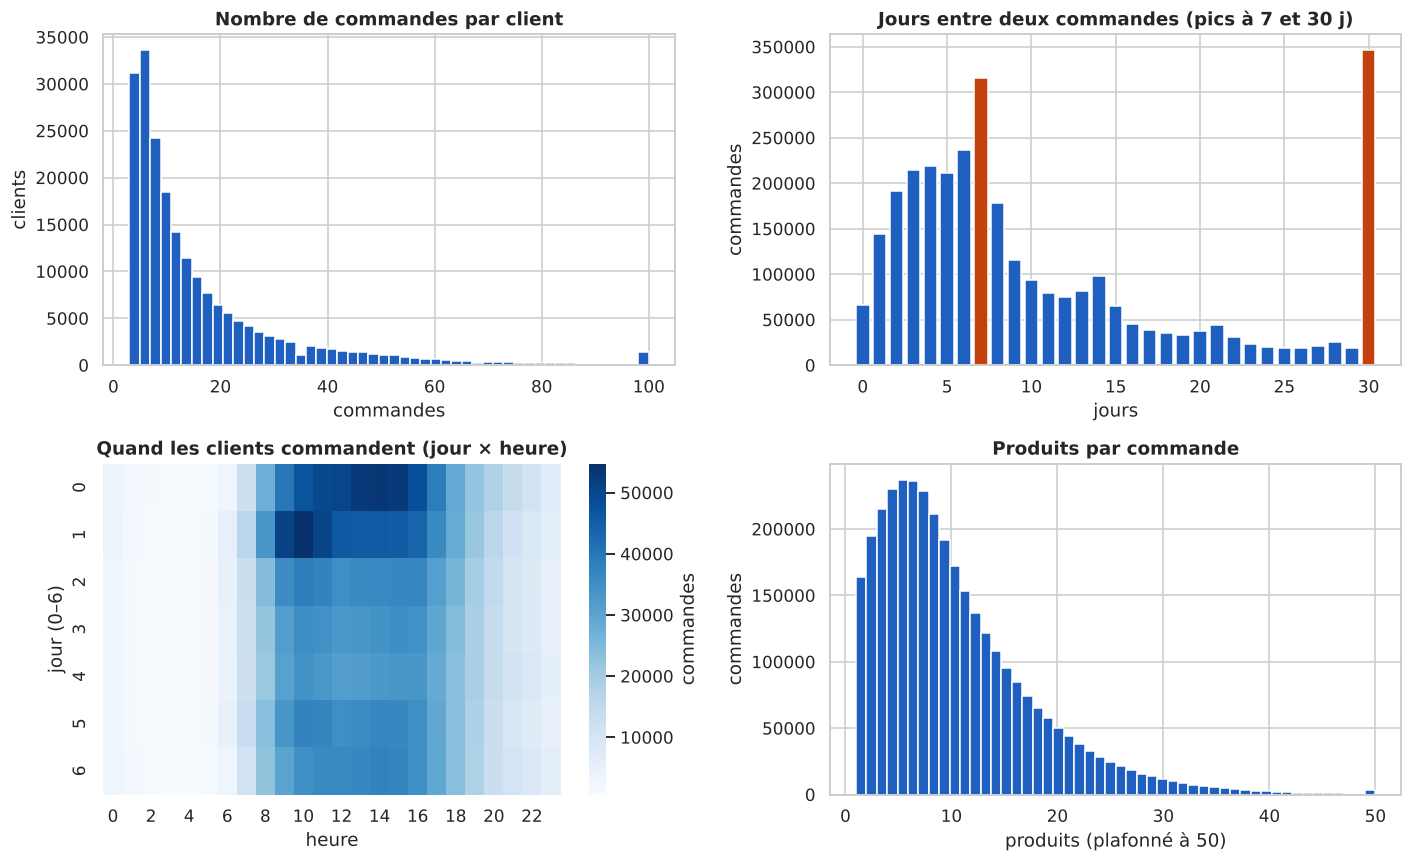

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
ax = axes[0, 0]
ax.hist(per_user["n_commandes"], bins=50, color=BLUE)
ax.set(title="Nombre de commandes par client", xlabel="commandes", ylabel="clients")

ax = axes[0, 1]
vc = orders_ok["days_since_prior_order"].value_counts().sort_index()
ax.bar(vc.index, vc.values, color=[ORANGE if d in (7, 30) else BLUE for d in vc.index])
ax.set(title="Jours entre deux commandes (pics à 7 et 30 j)", xlabel="jours", ylabel="commandes")

ax = axes[1, 0]
heat = orders_ok.pivot_table(index="order_dow", columns="order_hour_of_day", values="order_id", aggfunc="count")
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "commandes"})
ax.set(title="Quand les clients commandent (jour × heure)", xlabel="heure", ylabel="jour (0–6)")

ax = axes[1, 1]
ax.hist(basket.clip(upper=50), bins=50, color=BLUE)
ax.set(title="Produits par commande", xlabel="produits (plafonné à 50)", ylabel="commandes")
plt.tight_layout(); plt.show()

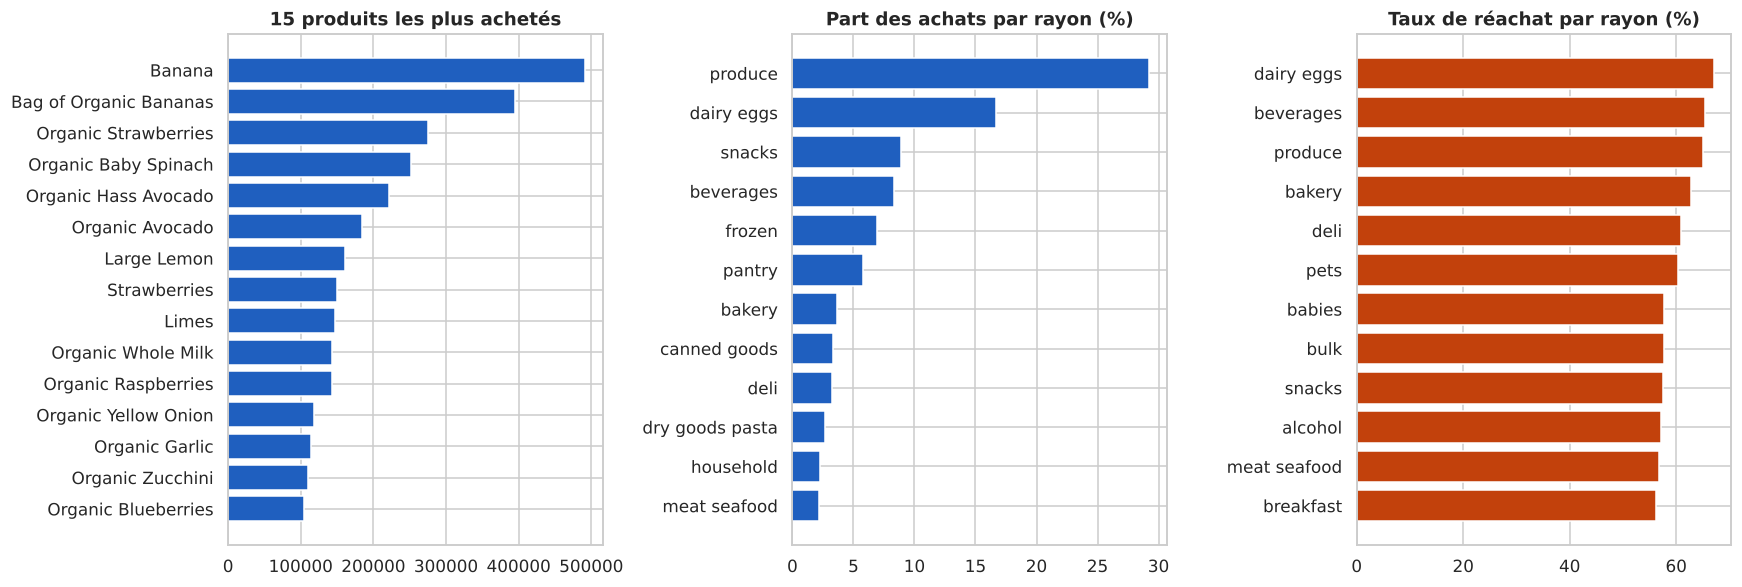

In [8]:
cat = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")
noms = cat.set_index("product_id")["product_name"]
dep_id = items["product_id"].map(cat.set_index("product_id")["department_id"]).astype("int8")
dep_nom = departments.set_index("department_id")["department"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
top = items["product_id"].value_counts().head(15)[::-1]
axes[0].barh(top.index.map(noms), top.values, color=BLUE); axes[0].set_title("15 produits les plus achetés")
dep = dep_id.value_counts(normalize=True).head(12)[::-1] * 100
axes[1].barh(dep.index.map(dep_nom), dep.values, color=BLUE); axes[1].set_title("Part des achats par rayon (%)")
reo = items["reordered"].groupby(dep_id).mean().sort_values().tail(12) * 100
axes[2].barh(reo.index.map(dep_nom), reo.values, color=ORANGE); axes[2].set_title("Taux de réachat par rayon (%)")
plt.tight_layout(); plt.show()
del dep_id

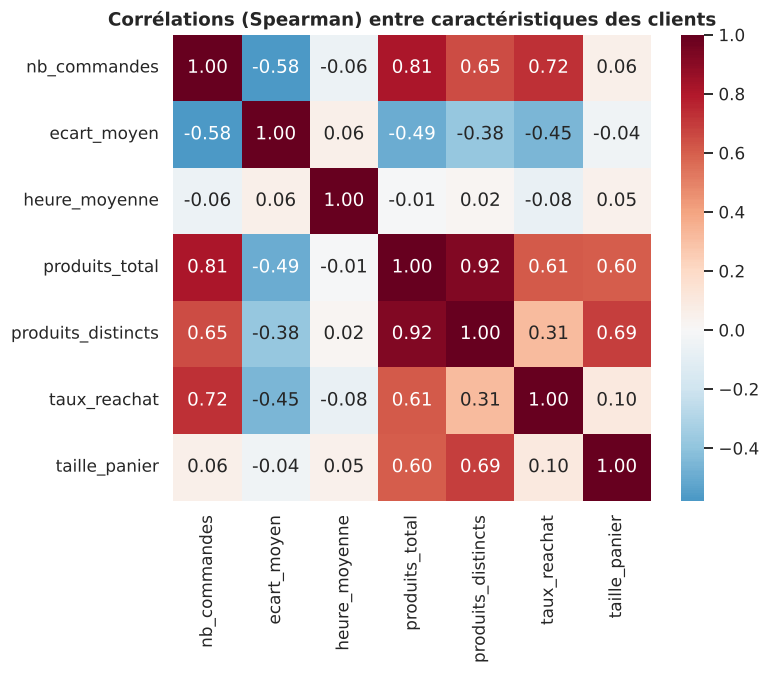

In [9]:
# Corrélations entre caractéristiques des clients
u = orders_ok.groupby("user_id").agg(nb_commandes=("order_id", "size"),
                                     ecart_moyen=("days_since_prior_order", "mean"),
                                     heure_moyenne=("order_hour_of_day", "mean"))
uid = items["order_id"].map(orders_ok.set_index("order_id")["user_id"]).astype("int32")
ub = pd.DataFrame({"user_id": uid, "product_id": items["product_id"], "reordered": items["reordered"]}).groupby("user_id").agg(
    produits_total=("product_id", "size"), produits_distincts=("product_id", "nunique"),
    taux_reachat=("reordered", "mean"))
del uid
u = u.join(ub)
u["taille_panier"] = u["produits_total"] / u["nb_commandes"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(u.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Corrélations (Spearman) entre caractéristiques des clients"); plt.show()

**Lecture** : *(commentaires rédigés à partir des résultats ci-dessus)*

- **Clients** : 16 commandes en moyenne (médiane 10, de 3 à 100). Beaucoup de clients occasionnels, quelques très fidèles (le pic à 100 est le plafond fixé par Instacart).
- **Rythme** : 11 jours en moyenne entre deux commandes (médiane 7). Deux pics : **7 jours** (les courses de la semaine) et **30 jours**. Ce dernier est un artefact : Instacart regroupe tous les écarts de 30 jours et plus à 30 (10,3 % des commandes).
- **Moment** : les commandes ont lieu surtout entre 9 h et 17 h, avec un pic les jours 0 et 1 (probablement le week-end). C'est la base du choix du moment d'envoi (§14).
- **Panier** : 10 produits en moyenne (médiane 8).
- **Réachat** : 59 % des produits achetés sont des réachats. La répétition est la norme, ce qui justifie SupplyMe.
- **Produits** : les fruits et légumes (29 % des achats) et les produits laitiers et œufs (17 %) dominent. Ce sont aussi les rayons les plus rachetés (environ 65 %). La banane est le produit n°1.
- **Corrélations** : plus un client commande souvent, plus il rachète les mêmes produits (ρ = 0,72) et plus l'écart entre ses commandes est court (ρ = −0,58). L'heure de commande n'est liée à rien (ρ ≈ 0) : c'est une habitude personnelle, pas un signe de fidélité.

## 4. Échantillon de travail et fusion des tables

On travaille sur les **3 000 vrais clients** de la base du groupe, tirés au hasard parmi les 206 209 clients d'Instacart (graine 20261118). Le tirage a été fait une fois pour tout le groupe : tout le monde travaille sur les mêmes clients.

On **fusionne** ensuite les 6 tables en une table unique : une ligne = un produit dans une commande, avec le client, la date, le produit, son rayon.

In [10]:
comptes = pd.read_excel(f"{BASE}/app/accounts.xlsx")
clients = np.sort(comptes.loc[comptes.origin == "observed_customer", "user_id"].astype(int).values)
N_CLIENTS = len(clients)
print(f"Clients réels de la base du groupe : {N_CLIENTS:,} · nouveaux comptes fictifs : {(comptes.origin == 'synthetic_new').sum():,}")

o = orders_ok[orders_ok.user_id.isin(clients)].sort_values(["user_id", "order_number"]).copy()
df = (items[items.order_id.isin(o.order_id)]
      .merge(o[["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day", "days_since_prior_order"]], on="order_id")
      .merge(cat[["product_id", "product_name", "aisle", "department", "department_id"]], on="product_id"))
print(f"Table fusionnée : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
print("Valeurs manquantes après fusion (hors days_since_prior_order) :",
      int(df.drop(columns="days_since_prior_order").isna().sum().sum()))
display(df.head())

Clients réels de la base du groupe : 3,000 · nouveaux comptes fictifs : 1,000


Table fusionnée : 493,119 lignes × 13 colonnes
Valeurs manquantes après fusion (hors days_since_prior_order) : 0


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle,department,department_id
0,48,14129,1,0,172786,5,2,0,30.000,Organic Chicken Bone Broth,soup broth bouillon,canned goods,15
1,48,22298,2,1,172786,5,2,0,30.000,Yo Baby Organic Whole Milk Banana Mango Yogurt,yogurt,dairy eggs,16
2,48,17600,3,1,172786,5,2,0,30.000,"YoKids Squeezers Organic Low-Fat Yogurt, Straw...",yogurt,dairy eggs,16
3,48,6141,4,0,172786,5,2,0,30.000,Low Sodium Beef Broth,soup broth bouillon,canned goods,15
4,48,42169,5,0,172786,5,2,0,30.000,Organic Unrefined Toasted Sesame Oil,oils vinegars,pantry,13


## 5. Reconstruction des dates

Instacart ne donne **aucune date**, seulement l'écart avec la commande précédente. On reconstruit le calendrier de chaque client :

1. `jour` = somme cumulée des écarts (la 1re commande = jour 0) ;
2. on aligne les clients sur la fin de l'historique (`END_DATE`, 31 octobre 2026). Tous les clients ne commandent pas le même jour : la dernière commande de chacun est placée **entre 0 et 13 jours avant** le 31 octobre (décalage aléatoire, environ un cycle de commande, puisque l'écart moyen est de 11 jours). Ainsi, « aujourd'hui » tombe à un moment quelconque du cycle de chaque client ;
3. `date = END_DATE − (365 − jour)`.

Les **intervalles sont réels** ; seules les dates absolues sont une convention.

In [11]:
o["jour"] = o["days_since_prior_order"].fillna(0).groupby(o["user_id"]).cumsum()
decalage = pd.Series(np.random.default_rng(SEED + 2).integers(0, 14, N_CLIENTS), index=clients)
o["jour"] = o["jour"] - o.groupby("user_id")["jour"].transform("max") + 365 - o["user_id"].map(decalage)
o["date"] = END_DATE - pd.to_timedelta(365 - o["jour"], unit="D")
df = df.merge(o[["order_id", "jour", "date"]], on="order_id")

exemple = o[o.user_id == clients[0]][["order_number", "days_since_prior_order", "jour", "date"]].head(8)
print(f"Exemple — client {clients[0]} :"); display(exemple)
print("Période couverte :", o["date"].min().date(), "→", o["date"].max().date())

Exemple — client 23 :


,order_number,days_since_prior_order,jour,date
273,1,NaN,282.000,2026-08-09
274,2,9.000,291.000,2026-08-18
275,3,5.000,296.000,2026-08-23
276,4,30.000,326.000,2026-09-22
277,5,30.000,356.000,2026-10-22


Période couverte : 2025-10-19 → 2026-10-31


## 6. Données complémentaires justifiées

Instacart ne contient ni prix, ni coûts, ni taille des foyers. Plutôt que du hasard, chaque valeur est **ancrée sur une source officielle** :

| Information manquante | Méthode | Source |
|---|---|---|
| **Prix** | prix de référence par rayon, à partir des prix moyens américains relevés par l'administration (œufs, lait, pain, bananes, bœuf, poulet, café, salade) ; variation réaliste entre produits d'un même rayon | U.S. Bureau of Labor Statistics, *Average Price Data* (U.S. city average, 2024–2026) |
| **Coût / marge** | marge brute moyenne de la distribution alimentaire : 27,9 % | NGA / FMS Solutions, *Independent Grocers Financial Survey* (exercice 2025) ; FMI : 30,5 % en 2020 |
| **Taille du foyer** | répartition officielle des foyers américains (1 pers. 33 %, 2 pers. 33 %, 3 pers. 14 %, 4 pers. 11 %, 5+ 9 %), attribuée selon la **taille réelle du panier** (gros paniers → foyers plus grands) | U.S. EIA, *Residential Energy Consumption Survey* 2024, table HC9.4 |
| **Effet d'une réduction** | élasticité-prix moyenne de −2,62 | Bijmolt, Van Heerde & Pieters (2005), *Journal of Marketing Research*, méta-analyse de 1 851 élasticités |
| **Quantités** | 1 unité par ligne (une ligne Instacart = un produit présent dans le panier) | structure d'Instacart |

Les données étant américaines, les montants sont exprimés en **dollars US ($)**.

,article BLS,prix_usd,période,rayon Instacart
0,"Œufs, gros, la douzaine",2.710,sept. 2025,dairy eggs
1,"Lait entier, le gallon",4.050,sept. 2025,dairy eggs
2,"Pain blanc, la livre",1.870,sept. 2025,bakery
3,"Bananes, la livre",0.650,août 2026,produce
4,"Salade iceberg, la livre",1.470,août 2026,produce
5,"Bœuf haché, la livre",6.920,août 2026,meat seafood
6,"Blanc de poulet, la livre",4.170,août 2026,meat seafood
7,"Café, la livre",6.320,2024,beverages


Prix de référence pour les rayons sans article BLS : 3.38 $ (médiane des ancres)


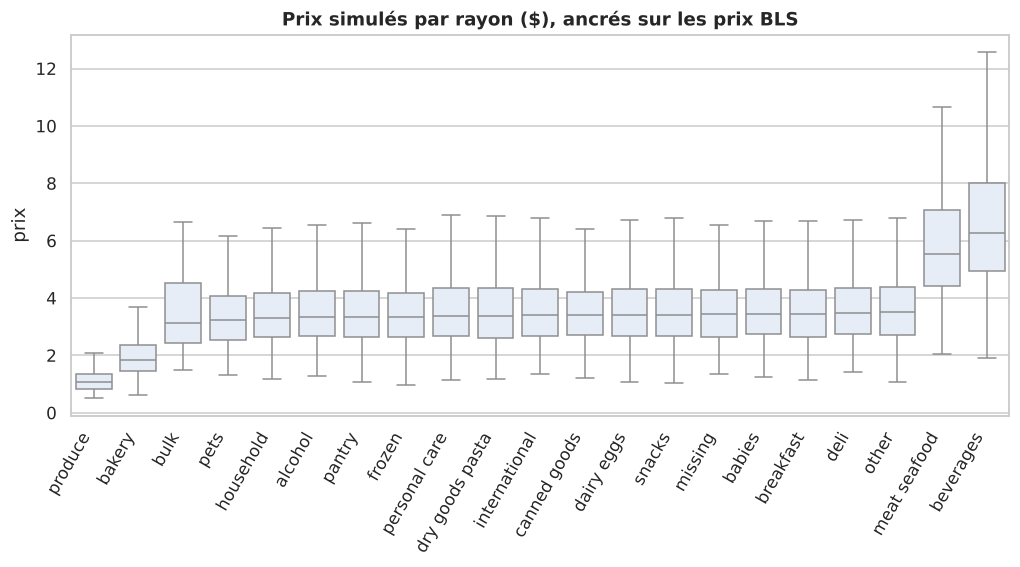

In [12]:
# Prix moyens relevés par le BLS (U.S. city average) — 1 unité de vente
ANCRES_BLS = pd.DataFrame([
    ("Œufs, gros, la douzaine",        2.71, "sept. 2025", "dairy eggs"),
    ("Lait entier, le gallon",          4.05, "sept. 2025", "dairy eggs"),
    ("Pain blanc, la livre",            1.87, "sept. 2025", "bakery"),
    ("Bananes, la livre",               0.65, "août 2026",  "produce"),
    ("Salade iceberg, la livre",        1.47, "août 2026",  "produce"),
    ("Bœuf haché, la livre",            6.92, "août 2026",  "meat seafood"),
    ("Blanc de poulet, la livre",       4.17, "août 2026",  "meat seafood"),
    ("Café, la livre",                  6.32, "2024",       "beverages"),
], columns=["article BLS", "prix_usd", "période", "rayon Instacart"])
display(ANCRES_BLS)

prix_rayon = ANCRES_BLS.groupby("rayon Instacart")["prix_usd"].mean()
PRIX_DEFAUT = ANCRES_BLS["prix_usd"].median()   # rayons sans article BLS : médiane des ancres
print(f"Prix de référence pour les rayons sans article BLS : {PRIX_DEFAUT:.2f} $ (médiane des ancres)")

MARGE_BRUTE = 0.279   # NGA / FMS Solutions 2025
cat_s = cat[cat.product_id.isin(df.product_id.unique())].copy()
rng = np.random.default_rng(SEED + 1)
ref = cat_s["department"].map(prix_rayon).fillna(PRIX_DEFAUT)
# variation entre produits d'un même rayon (log-normale, écart-type 0,35 : hypothèse)
cat_s["prix"] = (ref * rng.lognormal(0, 0.35, len(cat_s))).round(2).clip(lower=0.5)
cat_s["cout"] = (cat_s["prix"] * (1 - MARGE_BRUTE)).round(2)
cat_s["marge"] = cat_s["prix"] - cat_s["cout"]

plt.figure(figsize=(11, 4.5))
ordre = cat_s.groupby("department")["prix"].median().sort_values().index
sns.boxplot(data=cat_s, x="department", y="prix", order=ordre, color="#E3ECFA", showfliers=False)
plt.xticks(rotation=60, ha="right"); plt.title("Prix simulés par rayon ($), ancrés sur les prix BLS"); plt.xlabel("")
plt.show()

In [13]:
# Taille des foyers : répartition officielle (EIA RECS 2024, en millions de foyers)
RECS = pd.Series({1: 43.74, 2: 43.87, 3: 18.84, 4: 14.60, 5: 11.50})
part = RECS / RECS.sum()
taille_panier = df.groupby(["user_id", "order_id"]).size().groupby("user_id").mean()
# les clients sont classés par taille de panier, puis découpés selon les parts officielles
rang = taille_panier.rank(method="first", pct=True)
seuils = part.cumsum().values
foyer = pd.Series(np.searchsorted(seuils, rang.values, side="left") + 1, index=rang.index).clip(upper=5)
clients_df = pd.DataFrame({"taille_foyer": foyer, "taille_panier": taille_panier})

comparaison = pd.DataFrame({"source EIA (%)": (part * 100).round(1),
                            "échantillon (%)": (foyer.value_counts(normalize=True).sort_index() * 100).round(1),
                            "panier moyen (produits)": clients_df.groupby("taille_foyer")["taille_panier"].mean().round(1)})
comparaison.index.name = "personnes"
display(comparaison)

,source EIA (%),échantillon (%),panier moyen (produits)
personnes,,,
1,33.000,33.000,4.400
2,33.100,33.100,9.000
3,14.200,14.200,12.900
4,11.000,11.000,16.400
5,8.700,8.700,23.800


## 7. Volet 1 — Analyse des historiques d'achat des foyers

,commandes,depense_totale,panier_moyen,jours_entre_commandes,taille_foyer
count,"3,000.000","3,000.000","3,000.000","3,000.000","3,000.000"
mean,16.100,514.200,31.900,15.400,2.300
std,16.600,657.700,20.200,7.100,1.300
min,3.000,5.900,1.500,0.300,1.000
25%,6.000,134.600,18.100,9.400,1.000
50%,10.000,283.900,28.000,14.900,2.000
75%,20.000,607.700,40.900,20.500,3.000
max,100.000,"6,931.800",207.500,30.000,5.000


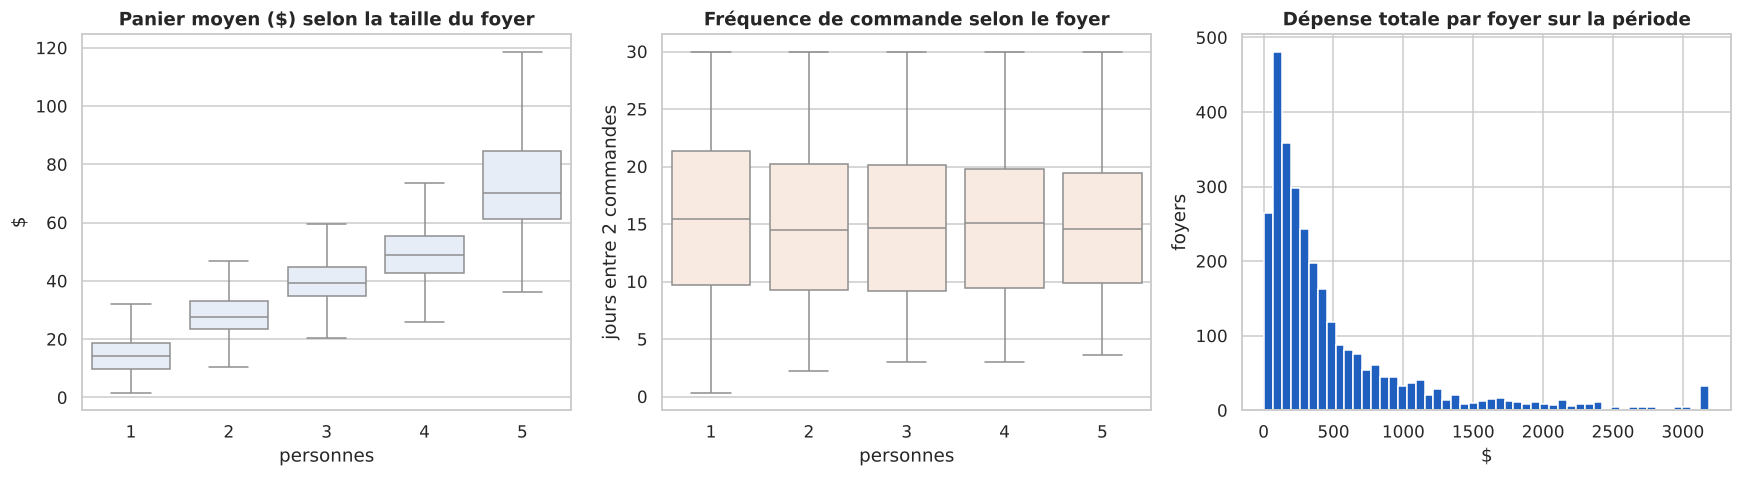

In [14]:
df = df.merge(cat_s[["product_id", "prix", "cout", "marge"]], on="product_id")
cmd = df.groupby(["user_id", "order_id"]).agg(montant=("prix", "sum"), produits=("product_id", "size")).reset_index()
hist = cmd.groupby("user_id").agg(commandes=("order_id", "size"), depense_totale=("montant", "sum"),
                                  panier_moyen=("montant", "mean"))
hist = hist.join(o.groupby("user_id")["days_since_prior_order"].mean().rename("jours_entre_commandes"))
hist = hist.join(clients_df["taille_foyer"])
display(hist.describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=hist, x="taille_foyer", y="panier_moyen", ax=axes[0], color="#E3ECFA", showfliers=False)
axes[0].set(title="Panier moyen ($) selon la taille du foyer", xlabel="personnes", ylabel="$")
sns.boxplot(data=hist, x="taille_foyer", y="jours_entre_commandes", ax=axes[1], color="#FCE9DC", showfliers=False)
axes[1].set(title="Fréquence de commande selon le foyer", xlabel="personnes", ylabel="jours entre 2 commandes")
axes[2].hist(hist["depense_totale"].clip(upper=hist["depense_totale"].quantile(0.99)), bins=50, color=BLUE)
axes[2].set(title="Dépense totale par foyer sur la période", xlabel="$", ylabel="foyers")
plt.tight_layout(); plt.show()

## 8. Volet 2 — Identifier les habitudes de consommation

Pour chaque couple **client × produit**, on calcule l'**intervalle entre deux achats** du même produit. Un produit acheté à intervalle régulier est une **habitude** : c'est exactement ce que SupplyMe cherche à anticiper.

La **régularité** est mesurée par le coefficient de variation (CV = écart-type ÷ moyenne des intervalles) : plus il est faible, plus l'habitude est régulière.

Couples client × produit achetés au moins 3 fois : 47,569


,% des habitudes
profil,
régulier,48.800
très régulier,31.100
irrégulier,20.100


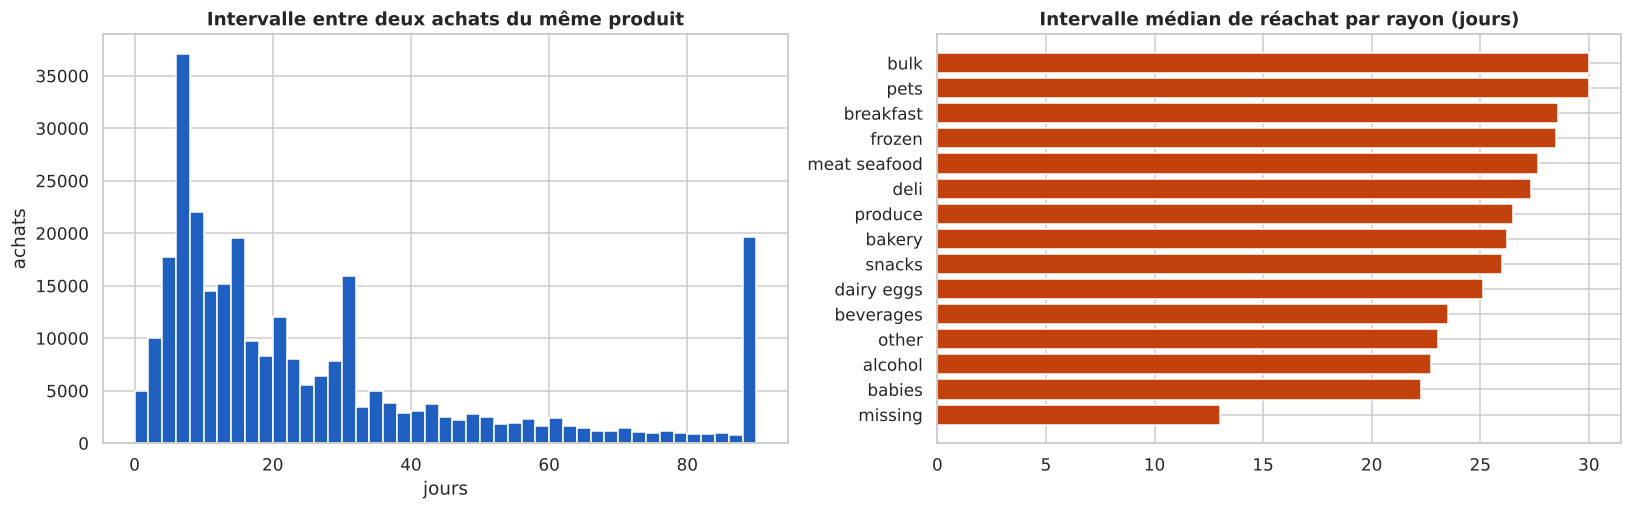

Exemple — les habitudes du client 97899 :


,produit,rayon,achats,intervalle_moyen,cv,profil
96916,Banana,produce,33,7.220,0.580,régulier
96906,2% Reduced Fat Milk,dairy eggs,33,8.190,0.610,régulier
96642,Mixed Bell Peppers,produce,32,8.450,0.610,régulier
96627,English Muffins,bakery,30,7.970,0.440,très régulier
96660,Cinnamon Swirl Raisin Bread,bakery,30,7.970,0.340,très régulier
97057,Apple Juice,beverages,30,9.000,0.630,régulier
97115,Split Top White Bread,bakery,28,8.300,0.390,très régulier
96739,Diet Coke Caffeine Free Soda,beverages,26,7.560,0.380,très régulier
96728,Broccoli Crown,produce,25,9.330,0.670,régulier
97156,Activia Peach/Strawberry Lowfat Yogurt,dairy eggs,23,9.860,0.580,régulier


In [15]:
ev = df[["user_id", "product_id", "order_number", "jour", "add_to_cart_order", "reordered", "department_id", "department", "product_name"]] \
    .sort_values(["user_id", "product_id", "jour"]).reset_index(drop=True)
ev["intervalle"] = ev.groupby(["user_id", "product_id"])["jour"].diff()

hab = ev.groupby(["user_id", "product_id"]).agg(achats=("jour", "size"), intervalle_moyen=("intervalle", "mean"),
                                                 intervalle_sd=("intervalle", "std"), rayon=("department", "first"),
                                                 produit=("product_name", "first")).reset_index()
hab = hab[hab.achats >= 3].copy()
hab["cv"] = hab["intervalle_sd"] / hab["intervalle_moyen"].clip(lower=1)
hab["profil"] = pd.cut(hab["cv"], [-0.01, 0.5, 1.0, np.inf], labels=["très régulier", "régulier", "irrégulier"])
print(f"Couples client × produit achetés au moins 3 fois : {len(hab):,}")
display(hab["profil"].value_counts(normalize=True).mul(100).round(1).to_frame("% des habitudes"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].hist(ev["intervalle"].dropna().clip(upper=90), bins=45, color=BLUE)
axes[0].set(title="Intervalle entre deux achats du même produit", xlabel="jours", ylabel="achats")
med = hab.groupby("rayon")["intervalle_moyen"].median().sort_values().head(15)
axes[1].barh(med.index, med.values, color=ORANGE)
axes[1].set(title="Intervalle médian de réachat par rayon (jours)")
plt.tight_layout(); plt.show()

client_ex = hab.groupby("user_id").size().idxmax()
print(f"Exemple — les habitudes du client {client_ex} :")
display(hab[hab.user_id == client_ex].sort_values("achats", ascending=False)
        [["produit", "rayon", "achats", "intervalle_moyen", "cv", "profil"]].head(10).round(2))

## 9. Variables explicatives et séparation train / test

### Le principe : des « photos » dans le temps (snapshots)
On se place à une date passée *s* (une « photo »). Les variables sont calculées **uniquement avec les achats antérieurs à *s*** ; la réponse à prédire est ce qui se passe **après *s***.

Deux cibles :
- **régression** : `jours_avant_prochain_achat` du produit ;
- **classification** : `achat_sous_7j` = 1 si le produit est racheté dans les 7 jours (utile pour décider d'une relance).

### Pourquoi une séparation **temporelle** et pas aléatoire ?
Une séparation aléatoire mélangerait passé et futur : le modèle « verrait l'avenir » et ses scores seraient faussement bons (**fuite d'information**). Ici :
- **train** : 12 photos, de janvier à juin ;
- **pause de 60 jours** (les réponses du train ne débordent jamais sur le test) ;
- **test** : 3 photos, en août et septembre, jamais vues pendant l'entraînement.

### La censure
Si le produit n'est pas racheté dans les 60 jours, on ne connaît pas le délai : l'observation est exclue de la régression mais gardée pour la classification (réponse = 0).

In [16]:
H, W = 60, 7   # horizon d'observation (jours) et fenêtre de la classification

def construire_variables(s, avec_cible=True, achats_min=2, achats_max=None):
    h, oh = ev[ev.jour <= s], o[o.jour <= s]
    cle = ["user_id", "product_id"]
    g = h.groupby(cle)
    f = g.agg(n_achats=("jour", "size"), premier=("jour", "min"), dernier=("jour", "max"),
              intervalle_moyen=("intervalle", "mean"), intervalle_median=("intervalle", "median"),
              intervalle_sd=("intervalle", "std"), dernier_intervalle=("intervalle", "last"),
              position_panier=("add_to_cart_order", "mean"), derniere_cmd=("order_number", "max"),
              premiere_cmd=("order_number", "min"), rayon=("department_id", "first")).reset_index()
    f = f[(f.n_achats >= achats_min) & (f.n_achats <= (achats_max or np.inf))]
    uc = oh.groupby("user_id").agg(cl_commandes=("order_id", "size"), cl_ecart_moyen=("days_since_prior_order", "mean"),
                                   cl_ecart_sd=("days_since_prior_order", "std"), cl_derniere=("jour", "max"),
                                   cl_num_cmd=("order_number", "max")).reset_index()
    ua = h.groupby("user_id").agg(cl_lignes=("product_id", "size"), cl_produits_distincts=("product_id", "nunique"),
                                  cl_taux_reachat=("reordered", "mean")).reset_index()
    uc = uc.merge(ua, on="user_id")
    uc["cl_taille_panier"] = uc["cl_lignes"] / uc["cl_commandes"]
    f = f.merge(uc, on="user_id")
    rec = h[h.order_number > h.user_id.map(uc.set_index("user_id")["cl_num_cmd"]) - 5].groupby(cle).size().rename("part_5_dernieres")
    f = f.merge(rec, left_on=cle, right_index=True, how="left")
    f["part_5_dernieres"] = f["part_5_dernieres"].fillna(0) / 5
    f["jours_depuis_achat"] = s - f["dernier"]
    f["cl_jours_depuis_cmd"] = s - f["cl_derniere"]
    f["indice_retard"] = f["jours_depuis_achat"] / f["intervalle_moyen"].clip(lower=1)
    f["cl_indice_retard"] = f["cl_jours_depuis_cmd"] / f["cl_ecart_moyen"].clip(lower=1)
    f["commandes_depuis_achat"] = f["cl_num_cmd"] - f["derniere_cmd"]
    f["taux_presence"] = f["n_achats"] / (f["cl_num_cmd"] - f["premiere_cmd"] + 1)
    f["frequence_mois"] = (f["n_achats"] - 1) / (f["dernier"] - f["premier"]).clip(lower=1) * 30
    p = h.groupby("product_id").agg(pr_taux_reachat=("reordered", "mean"), pr_acheteurs=("user_id", "nunique"),
                                    pr_intervalle_median=("intervalle", "median")).reset_index()
    f = f.merge(p, on="product_id", how="left").merge(clients_df[["taille_foyer"]], left_on="user_id", right_index=True)
    f["snapshot"] = s
    if avec_cible:
        futur = ev[ev.jour > s].groupby(cle)["jour"].min().rename("prochain")
        f = f.merge(futur, left_on=cle, right_index=True, how="left")
        d = f["prochain"] - s
        f["jours_avant_prochain_achat"] = d
        f["censure"] = d.isna() | (d > H)
        f["achat_sous_7j"] = (d <= W).fillna(False).astype(int)
    return f

VARIABLES = ["jours_depuis_achat", "intervalle_moyen", "intervalle_median", "intervalle_sd", "dernier_intervalle",
             "indice_retard", "n_achats", "frequence_mois", "taux_presence", "part_5_dernieres", "commandes_depuis_achat",
             "position_panier", "cl_commandes", "cl_ecart_moyen", "cl_ecart_sd", "cl_jours_depuis_cmd", "cl_indice_retard",
             "cl_produits_distincts", "cl_taux_reachat", "cl_taille_panier", "taille_foyer",
             "pr_taux_reachat", "pr_acheteurs", "pr_intervalle_median", "rayon"]

snap_test = [365 - H - 14 * i for i in range(3)][::-1]
snap_train = [snap_test[0] - H - 14 * i for i in range(12)][::-1]
t0 = time.time()
TR = pd.concat([construire_variables(s) for s in snap_train], ignore_index=True)
TE = pd.concat([construire_variables(s) for s in snap_test], ignore_index=True)
for d_ in (TR, TE):
    d_[VARIABLES] = d_[VARIABLES].astype(float).fillna(-1)
print(f"Variables construites en {time.time()-t0:.0f} s")
print(f"Train : {len(TR):,} observations ({len(snap_train)} photos) | Test : {len(TE):,} ({len(snap_test)} photos)")
print(f"Part censurée (pas de réachat sous {H} j) — train : {TR.censure.mean():.1%} · test : {TE.censure.mean():.1%}")
print(f"Part d'achats sous 7 jours — train : {TR.achat_sous_7j.mean():.1%} · test : {TE.achat_sous_7j.mean():.1%}")

Variables construites en 3 s
Train : 214,685 observations (12 photos) | Test : 153,099 (3 photos)
Part censurée (pas de réachat sous 60 j) — train : 46.8% · test : 56.9%
Part d'achats sous 7 jours — train : 16.4% · test : 11.7%


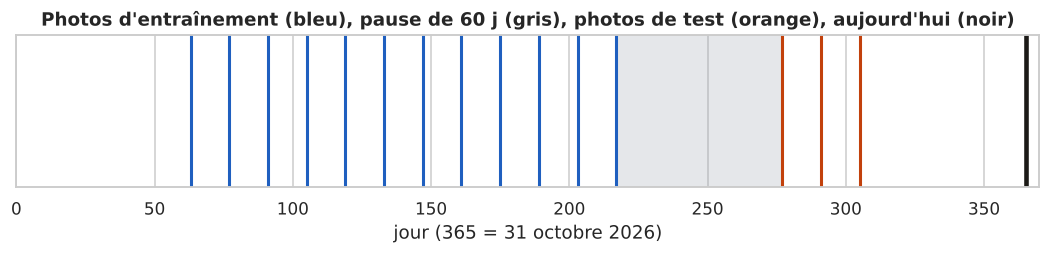

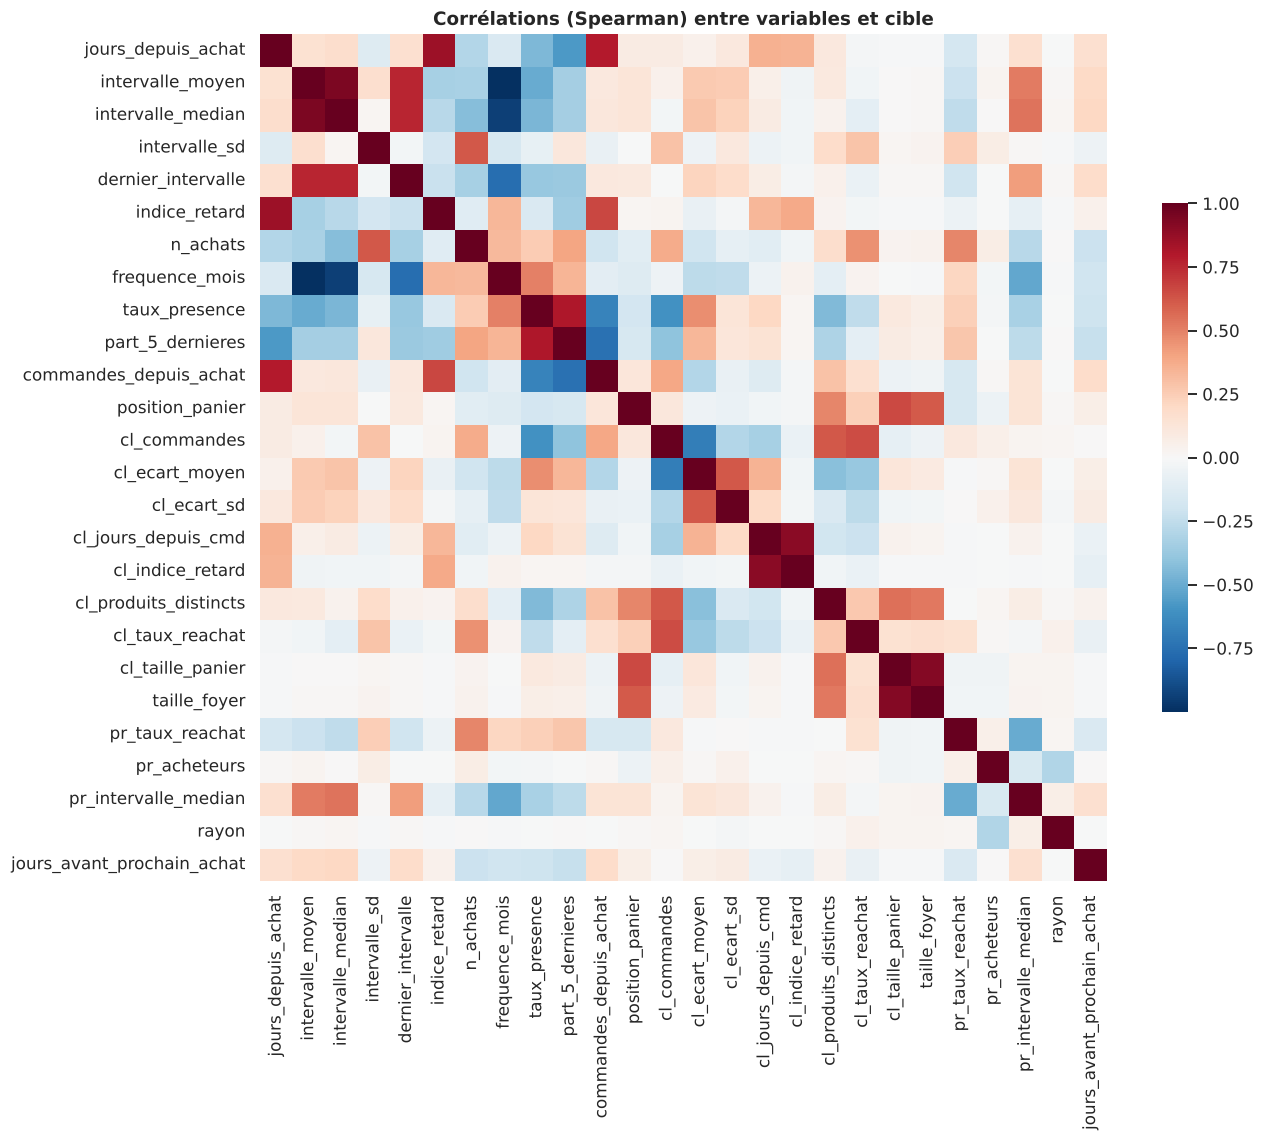

Variables les plus corrélées au délai avant le prochain achat :


,rho
part_5_dernieres,-0.231
n_achats,-0.213
intervalle_median,0.207
taux_presence,-0.205
intervalle_moyen,0.198
frequence_mois,-0.198
dernier_intervalle,0.180
commandes_depuis_achat,0.180


In [17]:
# Frise de la séparation temporelle
fig, ax = plt.subplots(figsize=(12, 1.8))
for s in snap_train: ax.axvline(s, color=BLUE, lw=2)
for s in snap_test: ax.axvline(s, color=ORANGE, lw=2)
ax.axvspan(max(snap_train), min(snap_test), color=GREY, alpha=0.25)
ax.axvline(365, color=DARK, lw=3)
ax.set_xlim(0, 370); ax.set_yticks([]); ax.set_xlabel("jour (365 = 31 octobre 2026)")
ax.set_title("Photos d'entraînement (bleu), pause de 60 j (gris), photos de test (orange), aujourd'hui (noir)")
plt.show()

corr = TR.loc[~TR.censure, VARIABLES + ["jours_avant_prochain_achat"]].sample(100_000, random_state=SEED).corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Corrélations (Spearman) entre variables et cible"); plt.show()
print("Variables les plus corrélées au délai avant le prochain achat :")
display(corr["jours_avant_prochain_achat"].drop("jours_avant_prochain_achat").sort_values(key=abs, ascending=False).head(8).round(3).to_frame("rho"))

## 10. Volet 3a — Prédire le délai avant le prochain achat (régression)

Cinq approches comparées sur la **même période de test** :

| Modèle | Idée |
|---|---|
| **Baseline** | règle de bon sens : intervalle médian habituel − jours écoulés |
| **Régression linéaire** | relation en ligne droite entre variables et délai |
| **Random Forest** | moyenne de nombreux arbres de décision |
| **XGBoost** | arbres construits les uns après les autres, chacun corrige les erreurs du précédent (*boosting*) |
| **LightGBM** | même principe que XGBoost, plus rapide sur de gros volumes |

Métriques : **MAE** (erreur moyenne en jours), **RMSE** (pénalise les grosses erreurs), **R²** (part de variance expliquée), **% à ±7 jours**.

In [18]:
tr_r, te_r = TR[~TR.censure], TE[~TE.censure]
Xtr, ytr = tr_r[VARIABLES], tr_r["jours_avant_prochain_achat"]
Xte, yte = te_r[VARIABLES], te_r["jours_avant_prochain_achat"]
ech = Xtr.sample(min(200_000, len(Xtr)), random_state=SEED).index   # sous-échantillon pour les modèles lents

def scores_reg(y, p):
    return {"MAE (j)": mean_absolute_error(y, p), "RMSE (j)": np.sqrt(mean_squared_error(y, p)),
            "R²": r2_score(y, p), "% à ±7 j": np.mean(np.abs(y - p) <= 7) * 100}

modeles_reg = {
    "Régression linéaire": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                                objective="reg:absoluteerror", tree_method="hist", n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, objective="l1", verbose=-1, random_state=SEED),
}
res_reg, preds_reg = {}, {}
preds_reg["Baseline"] = np.clip(te_r["intervalle_median"] - te_r["jours_depuis_achat"], 1, H)
res_reg["Baseline"] = scores_reg(yte, preds_reg["Baseline"])
for nom, m in modeles_reg.items():
    t0 = time.time()
    lent = nom in ("Random Forest",)
    m.fit(Xtr.loc[ech] if lent else Xtr, ytr.loc[ech] if lent else ytr)
    preds_reg[nom] = np.clip(m.predict(Xte), 1, H)
    res_reg[nom] = scores_reg(yte, preds_reg[nom])
    print(f"{nom:<20} entraîné en {time.time()-t0:5.1f} s")

tab_reg = pd.DataFrame(res_reg).T.sort_values("MAE (j)")
tab_reg["gain MAE vs baseline"] = (1 - tab_reg["MAE (j)"] / tab_reg.loc["Baseline", "MAE (j)"]) * 100
display(tab_reg.round(2))

Régression linéaire  entraîné en   0.2 s


Random Forest        entraîné en  42.5 s


XGBoost              entraîné en   5.1 s


LightGBM             entraîné en   5.9 s


,MAE (j),RMSE (j),R²,% à ±7 j,gain MAE vs baseline
LightGBM,12.110,15.700,0.030,38.750,30.610
Random Forest,12.190,15.050,0.110,33.550,30.170
Régression linéaire,12.250,15.140,0.100,33.170,29.820
XGBoost,12.250,15.540,0.050,36.180,29.800
Baseline,17.450,23.430,-1.160,35.670,0.000


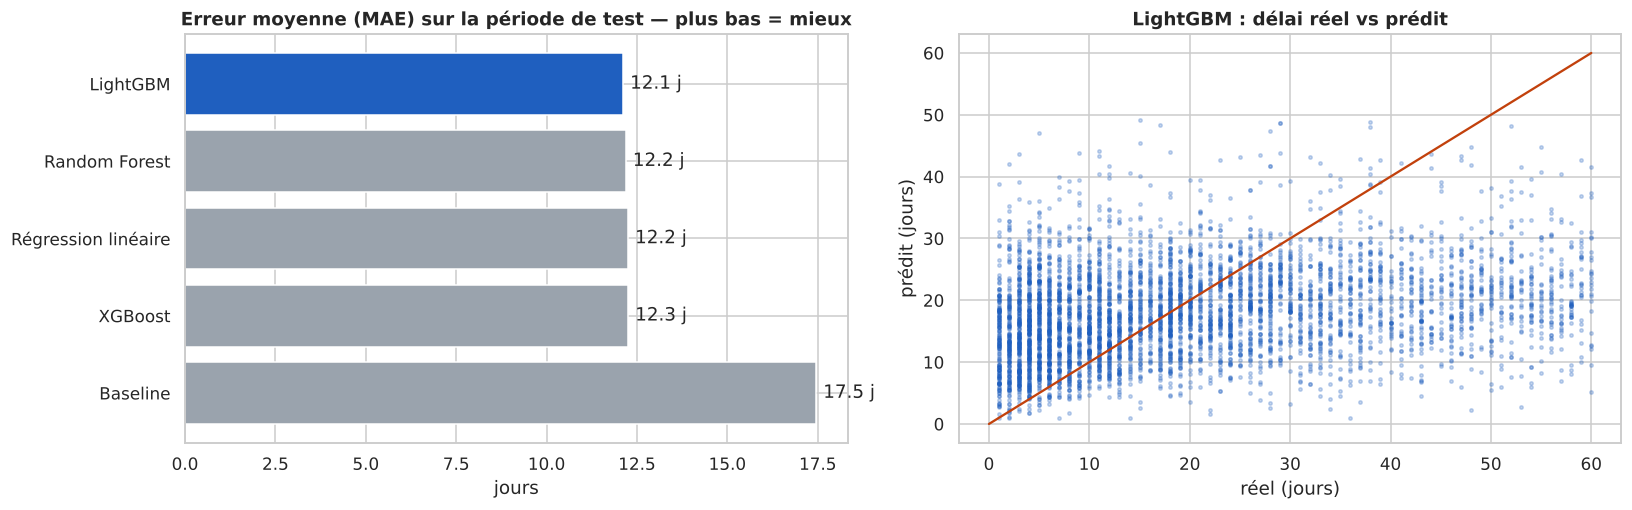

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
t = tab_reg.sort_values("MAE (j)", ascending=False)
axes[0].barh(t.index, t["MAE (j)"], color=[BLUE if i == t["MAE (j)"].idxmin() else GREY for i in t.index])
for i, v in enumerate(t["MAE (j)"]): axes[0].text(v + 0.2, i, f"{v:.1f} j", va="center")
axes[0].set(title="Erreur moyenne (MAE) sur la période de test — plus bas = mieux", xlabel="jours")
best_reg = tab_reg["MAE (j)"].idxmin()
ech_plot = np.random.default_rng(0).choice(len(yte), 5000, replace=False)
axes[1].scatter(yte.values[ech_plot], preds_reg[best_reg][ech_plot], s=5, alpha=0.25, color=BLUE)
axes[1].plot([0, H], [0, H], color=ORANGE)
axes[1].set(title=f"{best_reg} : délai réel vs prédit", xlabel="réel (jours)", ylabel="prédit (jours)")
plt.tight_layout(); plt.show()

## 11. Volet 3b — Probabilité de rachat sous 7 jours (classification)

C'est cette probabilité que le moteur marketing utilise. Métriques :
- **AUC** : probabilité que le modèle classe un acheteur au-dessus d'un non-acheteur (0,5 = hasard, 1 = parfait) ;
- **Average Precision** : qualité du classement des acheteurs (à comparer au taux de base) ;
- **Brier** : erreur des probabilités (plus bas = mieux calibré).

Régression logistique  entraîné en   0.4 s


Random Forest          entraîné en  79.7 s


XGBoost                entraîné en   7.5 s


LightGBM               entraîné en  18.4 s


Taux de base (achats sous 7 j dans le test) : 11.7%


,AUC,Average Precision,Brier
Random Forest,0.796,0.398,0.087
Régression logistique,0.789,0.372,0.088
LightGBM,0.779,0.371,0.089
XGBoost,0.777,0.368,0.089
Baseline,0.739,0.254,NaN


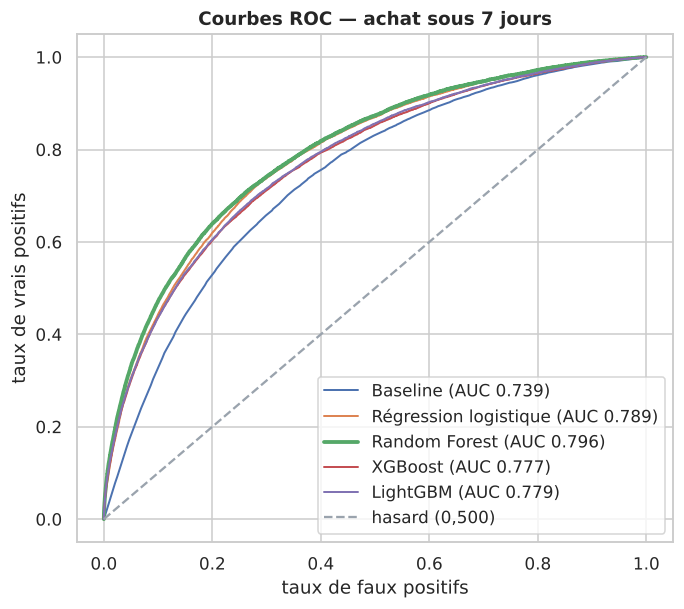

In [20]:
Xtr_c, ytr_c = TR[VARIABLES], TR["achat_sous_7j"]
Xte_c, yte_c = TE[VARIABLES], TE["achat_sous_7j"]
ech_c = Xtr_c.sample(min(200_000, len(Xtr_c)), random_state=SEED).index

modeles_cls = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                 tree_method="hist", eval_metric="auc", n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=63, min_child_samples=50, subsample=0.8,
                                   subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED),
}
res_cls, probas = {}, {}
# baseline : plus le produit est « en retard » sur son rythme habituel, plus l'achat est probable
probas["Baseline"] = -np.abs(TE["intervalle_median"] - TE["jours_depuis_achat"] - 3.5)
for nom, m in modeles_cls.items():
    t0 = time.time()
    lent = nom == "Random Forest"
    m.fit(Xtr_c.loc[ech_c] if lent else Xtr_c, ytr_c.loc[ech_c] if lent else ytr_c)
    probas[nom] = m.predict_proba(Xte_c)[:, 1]
    print(f"{nom:<22} entraîné en {time.time()-t0:5.1f} s")
for nom, p in probas.items():
    res_cls[nom] = {"AUC": roc_auc_score(yte_c, p), "Average Precision": average_precision_score(yte_c, p),
                    "Brier": brier_score_loss(yte_c, p) if nom != "Baseline" else np.nan}
tab_cls = pd.DataFrame(res_cls).T.sort_values("AUC", ascending=False)
print(f"Taux de base (achats sous 7 j dans le test) : {yte_c.mean():.1%}")
display(tab_cls.round(3))

plt.figure(figsize=(7, 6))
for nom, p in probas.items():
    fpr, tpr, _ = roc_curve(yte_c, p)
    plt.plot(fpr, tpr, lw=2.5 if nom == tab_cls.index[0] else 1.3, label=f"{nom} (AUC {res_cls[nom]['AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color=GREY, label="hasard (0,500)")
plt.xlabel("taux de faux positifs"); plt.ylabel("taux de vrais positifs")
plt.title("Courbes ROC — achat sous 7 jours"); plt.legend(loc="lower right"); plt.show()

## 12. Choix du modèle par validation

Le test ne doit servir qu'une fois. Pour **choisir** le modèle, on se crée une période de **validation** à l'intérieur du train : les modèles sont entraînés sur les premières photos et comparés sur les **3 dernières photos du train** (avec la même pause de 60 jours). On compare les 4 modèles et plusieurs réglages de LightGBM. Le gagnant est ensuite réentraîné sur tout le train et évalué une seule fois sur le test.

In [21]:
val_snaps = snap_train[-3:]
Fit, Val = TR[TR.snapshot <= val_snaps[0] - H], TR[TR.snapshot.isin(val_snaps)]
ech_v = Fit.sample(min(200_000, len(Fit)), random_state=SEED).index
grille = {
    "LightGBM (31 feuilles)": dict(num_leaves=31, learning_rate=0.05, n_estimators=600, min_child_samples=50),
    "LightGBM (63 feuilles, lent)": dict(num_leaves=63, learning_rate=0.02, n_estimators=1200, min_child_samples=200),
    "LightGBM (15 feuilles, régularisé)": dict(num_leaves=15, learning_rate=0.03, n_estimators=600, min_child_samples=300),
}
candidats = {nom: m for nom, m in modeles_cls.items()}
candidats.update({nom: lgb.LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1,
                                          random_state=SEED, **p) for nom, p in grille.items()})
val_auc = {}
for nom, m in candidats.items():
    from sklearn.base import clone
    m = clone(m)
    lent = nom == "Random Forest"
    m.fit(Fit.loc[ech_v, VARIABLES] if lent else Fit[VARIABLES], Fit.loc[ech_v, "achat_sous_7j"] if lent else Fit["achat_sous_7j"])
    val_auc[nom] = roc_auc_score(Val.achat_sous_7j, m.predict_proba(Val[VARIABLES])[:, 1])
    print(f"{nom:<36} AUC validation = {val_auc[nom]:.4f}")
val_auc = pd.Series(val_auc, name="AUC validation").sort_values(ascending=False)
MEILLEUR_CLS = val_auc.index[0]
print(f"\nModèle retenu sur la validation : {MEILLEUR_CLS}")

from sklearn.base import clone
clf_final = clone(candidats[MEILLEUR_CLS])
clf_final.fit(Xtr_c.loc[ech_c] if MEILLEUR_CLS == "Random Forest" else Xtr_c, ytr_c.loc[ech_c] if MEILLEUR_CLS == "Random Forest" else ytr_c)
p_final = clf_final.predict_proba(Xte_c)[:, 1]
print(f"{MEILLEUR_CLS} — AUC test = {roc_auc_score(yte_c, p_final):.4f} · "
      f"Average Precision = {average_precision_score(yte_c, p_final):.3f} · Brier = {brier_score_loss(yte_c, p_final):.4f}")
reg_final = modeles_reg[best_reg] if best_reg != "Baseline" else modeles_reg["LightGBM"]

Régression logistique                AUC validation = 0.7674


Random Forest                        AUC validation = 0.7586


XGBoost                              AUC validation = 0.7360


LightGBM                             AUC validation = 0.7413


LightGBM (31 feuilles)               AUC validation = 0.7401


LightGBM (63 feuilles, lent)         AUC validation = 0.7402


LightGBM (15 feuilles, régularisé)   AUC validation = 0.7569

Modèle retenu sur la validation : Régression logistique


Régression logistique — AUC test = 0.7889 · Average Precision = 0.372 · Brier = 0.0885


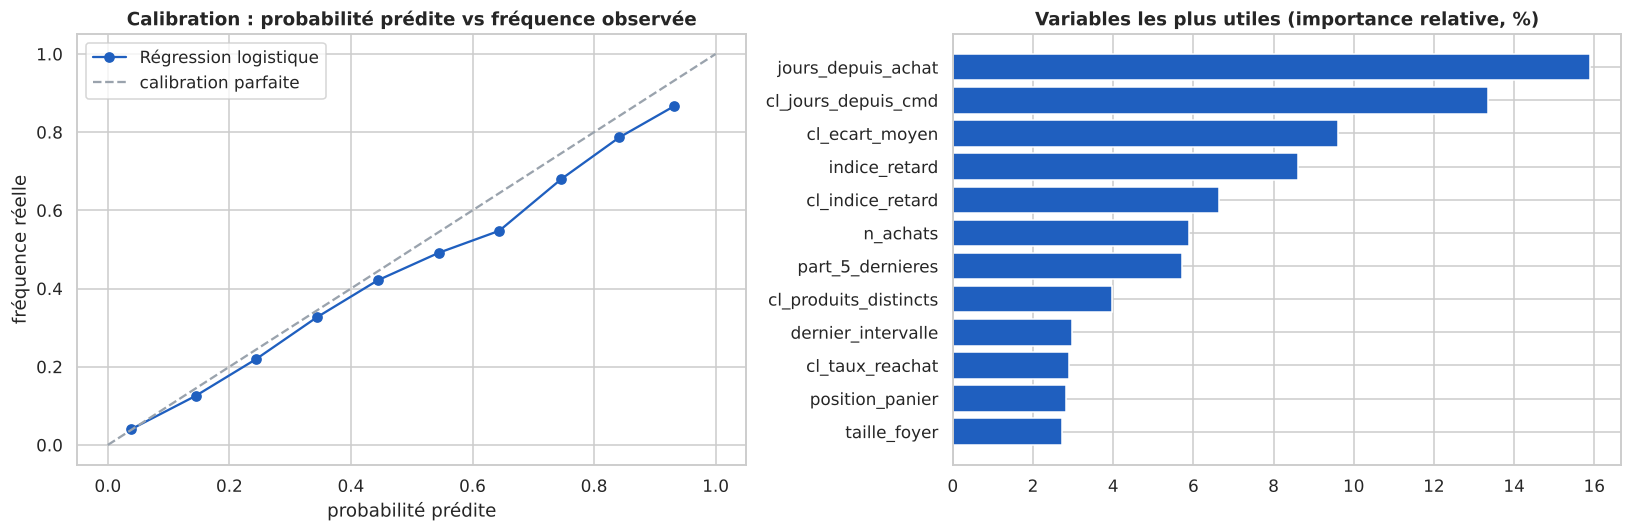

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
frac, moy = calibration_curve(yte_c, p_final, n_bins=10)
axes[0].plot(moy, frac, "o-", color=BLUE, label=MEILLEUR_CLS)
axes[0].plot([0, 1], [0, 1], "--", color=GREY, label="calibration parfaite")
axes[0].set(title="Calibration : probabilité prédite vs fréquence observée", xlabel="probabilité prédite", ylabel="fréquence réelle")
axes[0].legend()
modele_ = clf_final[-1] if hasattr(clf_final, "steps") else clf_final
poids = modele_.feature_importances_ if hasattr(modele_, "feature_importances_") else np.abs(modele_.coef_[0])
imp = pd.Series(poids, index=VARIABLES).sort_values()
imp = imp / imp.sum() * 100
axes[1].barh(imp.index[-12:], imp.values[-12:], color=BLUE)
axes[1].set(title="Variables les plus utiles (importance relative, %)")
plt.tight_layout(); plt.show()

### Pourquoi l'AUC ne monte pas à 0,95 ?

- **Le modèle retenu, la régression logistique, atteint une AUC de 0,789 sur le test** : 8 fois sur 10, un acheteur est classé au-dessus d'un non-acheteur. Son *average precision* (0,37) est **3,2 fois** supérieure au taux de base (11,7 %), et la règle simple ne fait que 0,739.
- **Pourquoi un modèle simple gagne-t-il ?** Avec 3 000 clients, les modèles complexes (LightGBM, XGBoost) apprennent aussi le « bruit » de la période d'entraînement. Sur la validation, la logistique fait mieux (0,767) que LightGBM (0,740 à 0,757). Le Random Forest est un peu meilleur sur le test (0,796), mais on ne choisit **jamais** un modèle en regardant le test : ce serait tricher.
- **Un plafond naturel** : savoir si un produit sera racheté dans les 7 jours dépend d'éléments invisibles (le placard, les imprévus, les achats en magasin). Tous les modèles se tiennent entre 0,777 et 0,796 : la limite vient de l'information disponible, pas du choix du modèle.
- **Un AUC de 0,95 serait suspect** : ce serait presque toujours le signe d'une fuite d'information. Notre séparation temporelle l'empêche.
- **Pour le délai**, LightGBM est le meilleur : 12,1 jours d'erreur contre 17,5 pour la règle simple (−31 %). Le R² est faible, car le délai exact d'un achat individuel est très bruité ; ce qui compte pour la décision, c'est de bien **classer** qui va acheter bientôt.

## 12 bis. Et les nouveaux clients, sans antécédents ? (démarrage à froid)

Le modèle principal s'appuie sur les habitudes **personnelles** du client (ses intervalles entre achats). Que faire pour un client qui vient d'arriver ? Trois situations :

| Situation | Ce qu'on sait | Réponse de SupplyMe |
|---|---|---|
| **0 commande** | rien sur le client | pas de prédiction individuelle : **panier de bienvenue** (produits les plus achetés et rachetés), avec éventuellement un court questionnaire (taille du foyer) ; objectif : obtenir la 1re commande |
| **1 achat d'un produit** | la date de cet achat, mais pas encore de rythme personnel | **modèle à froid** : on prédit avec l'expérience des **autres clients** (intervalle médian du produit, taux de réachat) et le rythme de commande du client |
| **2 achats et plus** | un rythme personnel | **modèle principal**, dont la précision augmente avec l'historique |

On vérifie chaque réponse sur les données.

In [23]:
# 0 commande vs 1 commande : quelle part du 2e panier peut-on deviner ?
p1 = df[df.order_number == 1].groupby("user_id")["product_id"].apply(set)
p2 = df[df.order_number == 2].groupby("user_id")["product_id"].apply(set)
uu = p1.index.intersection(p2.index)
top10 = set(df.groupby("product_id")["user_id"].nunique().nlargest(10).index)
couverture = pd.DataFrame({"part du 2e panier retrouvée": [
    np.mean([len(top10 & p2[i]) / len(p2[i]) for i in uu]),
    np.mean([len(p1[i] & p2[i]) / len(p2[i]) for i in uu])]},
    index=["0 commande : les 10 best-sellers", "1 commande : le 1er panier du client"])
display((couverture * 100).round(1).rename(columns=lambda c: c + " (%)"))

,part du 2e panier retrouvée (%)
0 commande : les 10 best-sellers,7.000
1 commande : le 1er panier du client,29.300


In [24]:
# 1 achat : le modèle à froid, entraîné et testé sur les produits achetés une seule fois
VAR_FROID = [v for v in VARIABLES if v not in ("intervalle_moyen", "intervalle_median", "intervalle_sd",
             "dernier_intervalle", "indice_retard", "n_achats", "frequence_mois")] + ["retard_vs_produit"]
def jeu_froid(snaps):
    d_ = pd.concat([construire_variables(s, achats_min=1, achats_max=1) for s in snaps], ignore_index=True)
    d_["retard_vs_produit"] = d_["jours_depuis_achat"] / d_["pr_intervalle_median"].clip(lower=1)
    d_[VAR_FROID] = d_[VAR_FROID].astype(float).fillna(-1)
    return d_
TRf, TEf = jeu_froid(snap_train), jeu_froid(snap_test)
print(f"Produits achetés une seule fois — train : {len(TRf):,} · test : {len(TEf):,} · rachat sous 7 j : {TEf.achat_sous_7j.mean():.1%}")

regle = -np.abs(TEf["pr_intervalle_median"] - TEf["jours_depuis_achat"] - 3.5)
froid = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                           subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=SEED).fit(TRf[VAR_FROID], TRf.achat_sous_7j)
p_froid = froid.predict_proba(TEf[VAR_FROID])[:, 1]
nc_tr, nc_te = TRf[~TRf.censure], TEf[~TEf.censure]
reg_froid = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, objective="l1", verbose=-1,
                              random_state=SEED).fit(nc_tr[VAR_FROID], nc_tr.jours_avant_prochain_achat)
tab_froid = pd.DataFrame({
    "AUC": [roc_auc_score(TEf.achat_sous_7j, regle), roc_auc_score(TEf.achat_sous_7j, p_froid)],
    "MAE délai (j)": [mean_absolute_error(nc_te.jours_avant_prochain_achat, np.clip(nc_te.pr_intervalle_median - nc_te.jours_depuis_achat, 1, H)),
                      mean_absolute_error(nc_te.jours_avant_prochain_achat, np.clip(reg_froid.predict(nc_te[VAR_FROID]), 1, H))]},
    index=["Règle : rythme des autres clients", "Modèle à froid (LightGBM)"])
display(tab_froid.round(3))

Produits achetés une seule fois — train : 327,865 · test : 235,052 · rachat sous 7 j : 2.9%


,AUC,MAE délai (j)
Règle : rythme des autres clients,0.697,22.166
Modèle à froid (LightGBM),0.742,13.921


,observations,AUC
historique,,
1–3,"5,002.000",0.717
4–5,"8,027.000",0.767
6–10,"21,774.000",0.754
11–20,"37,810.000",0.769
21 et +,"80,486.000",0.813


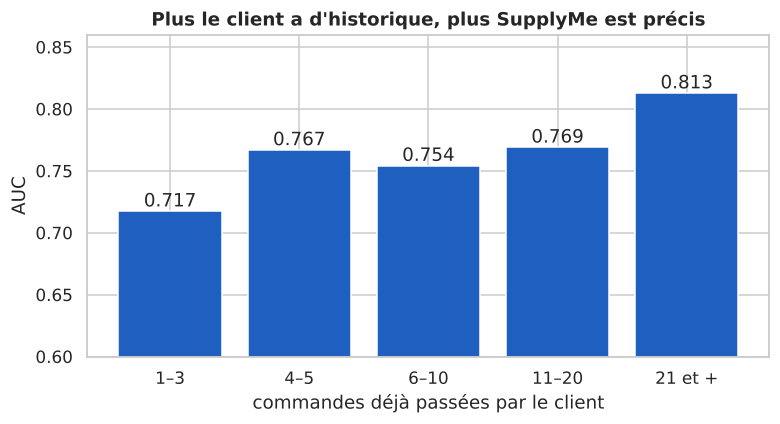

In [25]:
# 2 achats et plus : la précision du modèle principal augmente avec l'historique du client
hist_auc = (TE.assign(p=p_final, historique=pd.cut(TE["cl_commandes"], [0, 3, 5, 10, 20, 1000],
                                                   labels=["1–3", "4–5", "6–10", "11–20", "21 et +"]))
            .groupby("historique", observed=True)
            .apply(lambda g: pd.Series({"observations": len(g), "AUC": roc_auc_score(g.achat_sous_7j, g.p)})))
display(hist_auc.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(hist_auc.index.astype(str), hist_auc.AUC, color=BLUE)
for i, v in enumerate(hist_auc.AUC): ax.text(i, v + 0.004, f"{v:.3f}", ha="center")
ax.set(ylim=(0.6, 0.86), title="Plus le client a d'historique, plus SupplyMe est précis",
       xlabel="commandes déjà passées par le client", ylabel="AUC")
plt.show()

**Lecture :**

- **0 commande** : les 10 best-sellers ne retrouvent que **7 %** du 2e panier d'un client, alors que son propre 1er panier en retrouve **29 %**. Une seule commande apporte donc 4 fois plus d'information que la popularité : l'enjeu avec un nouveau client est d'obtenir **vite** sa 1re commande.
- **1 achat d'un produit** : en s'appuyant sur l'expérience des autres clients, le **modèle à froid** atteint une AUC de **0,742**, contre 0,697 pour la règle simple. Il réduit l'erreur sur le délai de **22,2 à 13,9 jours** (−37 %).
- **2 achats et plus** : la précision du modèle principal augmente avec l'historique du client, de 0,717 (1 à 3 commandes) à **0,813** (21 commandes et plus). Plus le client achète, mieux SupplyMe le connaît.

## 12 ter. Nouveaux clients sans aucune commande : panier de bienvenue, questionnaire et points

Pour un client qui n'a encore rien acheté, SupplyMe procède en trois temps :

1. **Panier de bienvenue** : les produits que les autres clients achètent **et rachètent** le plus (score = nombre d'acheteurs × taux de réachat).
2. **Questionnaire d'accueil** : le client indique ses rayons préférés (jusqu'à 3), la taille de son foyer, son régime et sa fréquence de courses. Chaque rayon indiqué rapporte **10 points**, plus **50 points de bonus** si les 3 rayons sont renseignés (100 points = 1 $ de réduction sur la 1re commande). Ce coût est compté.
3. **Personnalisation** : les 10 places du panier sont réparties entre les rayons au prorata des préférences **lissées** (Dirichlet, α = 30, choisi par validation dans la base du groupe) : p_d = (1{d choisi} + α·q_d) / (k + α). Sans réponse, on retombe sur la moyenne des clients.

**Évaluation sur données réelles** : les 1 500 clients « holdout » de la base du groupe jouent les nouveaux clients ; on ne regarde que leur **1re commande réelle** et on mesure la part retrouvée par le panier proposé (Recall@10). Les réponses au questionnaire n'existant pas dans Instacart, elles sont **simulées** pour cette évaluation à partir des achats ultérieurs du client (avec du bruit et 15 % de réponses inexactes), et comparées à un **placebo** (réponses d'un autre client).

In [26]:
POINTS_PAR_RAYON, BONUS_COMPLET, VALEUR_POINT, ALPHA = 10, 50, 0.01, 30
def points(n): return n * POINTS_PAR_RAYON + (BONUS_COMPLET if n >= 3 else 0)

def classement_bienvenue(d_):
    p = d_.groupby("product_id").agg(acheteurs=("user_id", "nunique"), lignes=("order_id", "size"),
                                     reachats=("reordered", "sum"), rayon=("department", "first"), produit=("product_name", "first"))
    p["taux_reachat"] = (p.reachats + 1) / (p.lignes + 2)
    p["score"] = p.acheteurs * p.taux_reachat
    return p.sort_values("score", ascending=False)

def preferences_lissees(rayons, q, alpha=ALPHA):
    c = pd.Series(0.0, index=q.index); c[[r for r in rayons if r in c.index]] = 1.0
    return (c + alpha * q) / (len(rayons) + alpha)

def panier_personnalise(classement, pref, n=10):
    cible = pref.reindex(classement.rayon.unique()).fillna(0); cible = cible / cible.sum() * n
    places = np.floor(cible).astype(int); places[(cible - places).nlargest(n - places.sum()).index] += 1
    return [pid for rayon, k in places[places > 0].items() for pid in classement.index[classement.rayon == rayon][:k]]

split = pd.read_excel(f"{BASE}/audit/customer_split.xlsx")
holdout = set(split.loc[split.split == "holdout", "user_id"])
connus, nouveaux_df = df[~df.user_id.isin(holdout)], df[df.user_id.isin(holdout)]
classement = classement_bienvenue(connus)
q = connus.department.value_counts() + 0.5; q = q / q.sum()
premiere = nouveaux_df[nouveaux_df.order_number == 1].groupby("user_id").product_id.apply(set)

rng_q = np.random.default_rng(SEED + 4)
apres = {u: g.value_counts() for u, g in nouveaux_df[nouveaux_df.order_number > 1].groupby("user_id").department}
reponses = {}
for u in premiere.index:
    if u in apres:
        v = apres[u] * rng_q.lognormal(0, 0.6, len(apres[u])); choix = list(v.nlargest(3).index)
        if rng_q.random() < 0.15: choix[-1] = rng_q.choice([r for r in q.index if r not in choix])
        reponses[u] = choix
users_q = [u for u in premiere.index if u in reponses]
placebo = dict(zip(users_q, [reponses[u] for u in rng_q.permutation(users_q)]))
pop10 = list(connus.groupby("product_id").user_id.nunique().nlargest(10).index)
rappel = lambda recos: np.mean([len(set(recos[u]) & premiere[u]) / len(premiere[u]) for u in users_q]) * 100
eval_bienvenue = pd.DataFrame({"Recall@10 (%)": {
    "Les 10 produits les plus achetés": rappel({u: pop10 for u in users_q}),
    "Panier de bienvenue (achetés et rachetés)": rappel({u: list(classement.index[:10]) for u in users_q}),
    "Panier réparti par rayon, sans réponse": rappel({u: panier_personnalise(classement, q) for u in users_q}),
    "Panier réparti par rayon, avec questionnaire (simulé)": rappel({u: panier_personnalise(classement, preferences_lissees(reponses[u], q)) for u in users_q}),
    "Placebo : réponses d'un autre client": rappel({u: panier_personnalise(classement, preferences_lissees(placebo[u], q)) for u in users_q}),
}})
print(f"Nouveaux clients évalués : {len(users_q):,}")
display(eval_bienvenue.round(2))
print("Le panier de bienvenue :")
display(classement.head(10)[["produit", "rayon", "acheteurs", "taux_reachat"]].round(3))

Nouveaux clients évalués : 1,500


,Recall@10 (%)
Les 10 produits les plus achetés,7.130
Panier de bienvenue (achetés et rachetés),7.130
"Panier réparti par rayon, sans réponse",5.000
"Panier réparti par rayon, avec questionnaire (simulé)",5.130
Placebo : réponses d'un autre client,4.940


Le panier de bienvenue :


,produit,rayon,acheteurs,taux_reachat
product_id,,,,
24852,Banana,produce,555,0.841
13176,Bag of Organic Bananas,produce,470,0.849
21137,Organic Strawberries,produce,442,0.758
21903,Organic Baby Spinach,produce,421,0.774
47209,Organic Hass Avocado,produce,313,0.790
16797,Strawberries,produce,333,0.708
47626,Large Lemon,produce,334,0.699
26209,Limes,produce,335,0.687
47766,Organic Avocado,produce,305,0.747


In [27]:
# Les 1 000 nouveaux comptes du groupe : réponses, points gagnés et panier personnalisé
nc = comptes[comptes.origin == "synthetic_new"][["account_id", "onboarding_state"]].copy()
rep_ = pd.read_excel(f"{BASE}/app/onboarding_answers.xlsx").merge(departments, on="department_id")
nc["rayons"] = nc.account_id.map(rep_.groupby("account_id").department.apply(list)).apply(lambda v: v if isinstance(v, list) else [])
nc["nb_reponses"] = nc.rayons.str.len()
nc["points"] = nc.nb_reponses.apply(points)
nc["valeur ($)"] = nc.points * VALEUR_POINT
display(nc.groupby("nb_reponses").agg(comptes=("account_id", "size"), points=("points", "first"), valeur=("valeur ($)", "first")))
print(f"Coût moyen des points par nouveau compte : {nc['valeur ($)'].mean():.2f} $")

exemple_nc = nc[nc.nb_reponses == 3].iloc[0]
print(f"\nExemple — compte {exemple_nc.account_id}, rayons choisis : {', '.join(exemple_nc.rayons)}")
classement_tous = classement_bienvenue(df)
q_tous = df.department.value_counts() + 0.5; q_tous = q_tous / q_tous.sum()
display(classement_tous.loc[panier_personnalise(classement_tous, preferences_lissees(exemple_nc.rayons, q_tous)), ["produit", "rayon"]])

assoc = pd.read_excel(f"{BASE}/app/product_associations.xlsx")
print("Produits complémentaires (vrais co-achats, base du groupe) — exemple pour le 1er produit du panier :")
p0_ = classement_tous.index[0]
display(assoc[assoc.product_id == p0_].nlargest(5, "lift").assign(complement=lambda d: d.related_product_id.map(cat.set_index("product_id").product_name))
        [["complement", "co_purchases", "confidence", "lift"]].round(3))

,comptes,points,valeur
nb_reponses,,,
0,334,0,0.000
1,333,10,0.100
3,333,80,0.800


Coût moyen des points par nouveau compte : 0.30 $

Exemple — compte N00002, rayons choisis : deli, produce, snacks


,produit,rayon
product_id,,
24852,Banana,produce
13176,Bag of Organic Bananas,produce
21137,Organic Strawberries,produce
27845,Organic Whole Milk,dairy eggs
49235,Organic Half & Half,dairy eggs
30489,Original Hummus,deli
9076,Blueberries,frozen
44632,Sparkling Water Grapefruit,beverages
31506,Extra Virgin Olive Oil,pantry


Produits complémentaires (vrais co-achats, base du groupe) — exemple pour le 1er produit du panier :


,complement,co_purchases,confidence,lift
39741,Honeycrisp Apple,406,0.062,2.594
39739,Seedless Red Grapes,417,0.063,2.549
39740,Organic Fuji Apple,415,0.063,2.471
39733,Organic Avocado,683,0.104,2.218
39735,Strawberries,579,0.088,1.973


**Lecture :**

- **Pour une toute première commande, les best-sellers restent la meilleure proposition** : ils retrouvent 7,1 % des produits de la 1re commande réelle. Le panier « achetés et rachetés » fait aussi bien, avec des produits que le client gardera dans ses habitudes.
- **Le questionnaire apporte un petit signal réel** : avec des réponses, le panier réparti par rayon retrouve 5,13 %, contre 4,94 % avec les réponses d'un autre client (placebo). Mais répartir le panier entre les rayons coûte plus que ce que les réponses rapportent : la banane et les fraises sont achetées par presque tout le monde.
- **Conclusion pratique** : le questionnaire sert surtout à **connaître le client** (rayons, foyer, régime) et à **démarrer la relation**. Il coûte en moyenne 0,30 $ de points par nouveau compte, soit 0,80 $ pour un questionnaire complet. Le panier proposé reste fondé sur les best-sellers, enrichis par les **produits complémentaires** (vrais co-achats : banane → pommes, raisin, avocat).
- Les réponses étant fictives dans Instacart, cette partie est une **démonstration de la méthode** ; la 1re commande utilisée pour l'évaluation est, elle, réelle.

## 13. Prédiction à la date d'aujourd'hui

On applique les modèles retenus à la date d'analyse (31 octobre 2026) : pour chaque couple client × produit habituel, on obtient **la date probable du prochain achat** et **la probabilité d'achat dans les 7 jours**. Les modèles sont réentraînés sur toutes les données disponibles.

In [28]:
tout = pd.concat([TR, TE], ignore_index=True)
reg_final.fit(tout.loc[~tout.censure, VARIABLES], tout.loc[~tout.censure, "jours_avant_prochain_achat"])
clf_final.fit(tout[VARIABLES], tout["achat_sous_7j"]) if MEILLEUR_CLS != "Random Forest" else clf_final.fit(tout.sample(400_000, random_state=SEED)[VARIABLES], tout.sample(400_000, random_state=SEED)["achat_sous_7j"])

AUJ = 365
P = construire_variables(AUJ, avec_cible=False)
P[VARIABLES] = P[VARIABLES].astype(float).fillna(-1)
P["delai_predit"] = np.clip(reg_final.predict(P[VARIABLES]), 1, H)
P["proba_7j"] = clf_final.predict_proba(P[VARIABLES])[:, 1]
P["date_prevue"] = END_DATE + pd.to_timedelta(P["delai_predit"].round(), unit="D")
P = P.merge(cat_s[["product_id", "product_name", "department", "prix", "marge"]], on="product_id")
print(f"Prédictions : {len(P):,} couples client × produit")
display(P.sort_values("proba_7j", ascending=False)[["user_id", "product_name", "jours_depuis_achat", "intervalle_moyen",
                                                    "delai_predit", "date_prevue", "proba_7j"]].head(10).round(2))

Prédictions : 80,946 couples client × produit


,user_id,product_name,jours_depuis_achat,intervalle_moyen,delai_predit,date_prevue,proba_7j
11786,31606,Total 2% Lowfat Greek Strained Yogurt With Blu...,2.000,3.710,2.630,2026-11-03,0.990
11813,31606,Total 2% with Strawberry Lowfat Greek Strained...,2.000,4.010,2.870,2026-11-03,0.990
76061,192439,Bag of Organic Bananas,11.000,4.790,2.470,2026-11-02,0.970
11814,31606,Total 2% Lowfat Greek Strained Yogurt with Peach,2.000,4.740,3.410,2026-11-03,0.970
55835,142664,Golden Pineapple,2.000,5.510,6.250,2026-11-06,0.960
27437,70309,Banana,0.000,5.570,6.390,2026-11-06,0.960
42391,106580,100% Whole Wheat Bread,5.000,5.400,2.310,2026-11-02,0.960
27422,70309,Gluten and Dairy Free Rice Macaroni and Cheeze,0.000,5.370,6.540,2026-11-07,0.960
3935,10886,Bag of Organic Bananas,4.000,5.770,1.940,2026-11-02,0.950
4913,12899,Bag of Organic Bananas,7.000,5.820,5.130,2026-11-05,0.950


## 14. Volet 4 — Le meilleur moment pour contacter le client

Instacart fournit l'**heure** et le **jour** réels de chaque commande. Pour chaque client, on retient son **heure habituelle** (la plus fréquente) et son **jour habituel**.

**Règle d'envoi** : le message part **1 jour avant la date prévue du besoin**, **1 heure avant l'heure habituelle de commande** (le client a le temps de voir le message avant le moment où il commande d'habitude).

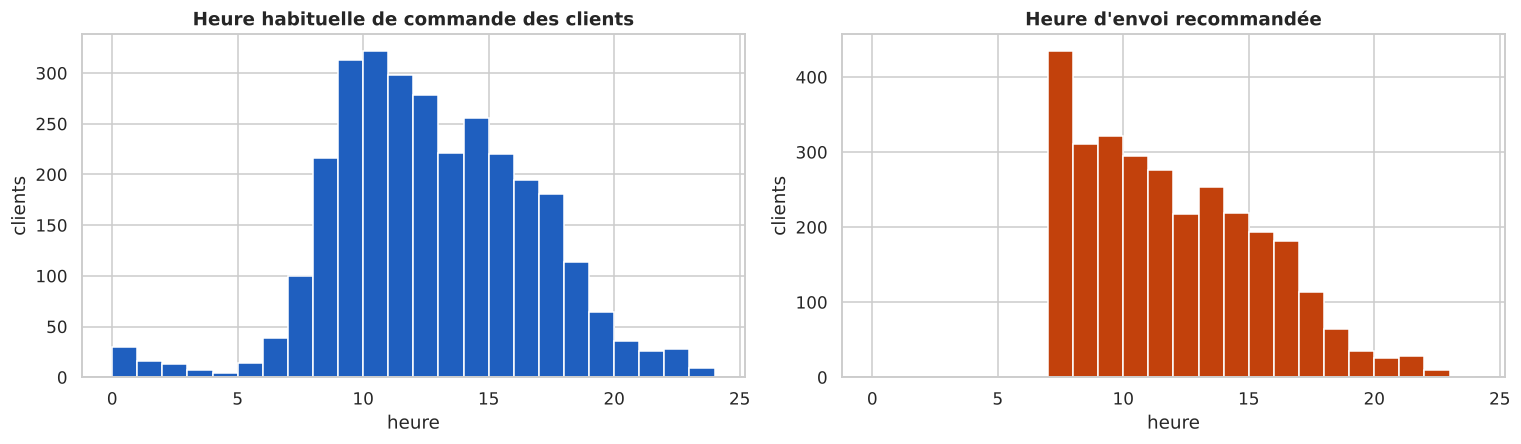

In [29]:
habit = o.groupby("user_id").agg(heure_habituelle=("order_hour_of_day", lambda s: int(s.mode().iloc[0])),
                                 jour_habituel=("order_dow", lambda s: int(s.mode().iloc[0])))
P = P.merge(habit, left_on="user_id", right_index=True)
P["date_envoi"] = (P["date_prevue"] - pd.Timedelta(days=1)).clip(lower=END_DATE + pd.Timedelta(days=1))
P["heure_envoi"] = (P["heure_habituelle"] - 1).clip(lower=7)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(habit["heure_habituelle"], bins=range(0, 25), color=BLUE)
axes[0].set(title="Heure habituelle de commande des clients", xlabel="heure", ylabel="clients")
axes[1].hist(P.drop_duplicates("user_id")["heure_envoi"], bins=range(0, 25), color=ORANGE)
axes[1].set(title="Heure d'envoi recommandée", xlabel="heure", ylabel="clients")
plt.tight_layout(); plt.show()

## 15. Volet 5 — Évaluer la pertinence d'une réduction

### Le modèle économique (raisonnement **incrémental**)
On ne compte que les achats **provoqués** par le message. Pour un produit de prix *R* et de marge *m* :

| Scénario | Probabilité d'achat | Profit incrémental |
|---|---|---|
| **A — Relance simple** | pA = p0 + u·(1 − p0) | (pA − p0)·V − c |
| **B — Relance + réduction d** | pB = min(pA·(1 + 2,62·d), 0,95) | pB·(V − d·R) − p0·V − c |
| **C — Aucune relance** | p0 | 0 |

**V = valeur d'un achat gagné.** Deux cas :
- **besoin imminent** (achat prévu sous 7 jours, habitude intacte) : V = m, la marge d'un seul achat ;
- **besoin dépassé** (une vraie habitude, achetée au moins 3 fois à un rythme régulier, mais aucun achat depuis 1,5 à 3 fois l'intervalle habituel : le client a peut-être acheté ailleurs) : le reconquérir, c'est **récupérer l'habitude** pour les 3 prochains mois. V = m × nombre d'achats attendus en 90 jours (90 ÷ intervalle habituel, plafonné à 6). C'est le raisonnement de la **valeur client** (*customer lifetime value*) : on investit dans une réduction pour sauver plusieurs achats futurs, pas un seul.

- **p0** : probabilité d'achat sans relance = **sortie du modèle retenu au §12** ;
- **2,62** : élasticité-prix moyenne de la méta-analyse de Bijmolt *et al.* (2005) : −10 % de prix ≈ +26 % de demande ;
- **u = 5 %** : part des clients hésitants convaincus par un simple rappel — **hypothèse**, testée de 0 à 10 % au §17 ;
- **c = 0,05 $** : coût d'un message (routage + outil CRM) — **hypothèse**, partagé entre les produits d'un même message.

La réduction est payée à **tous** les acheteurs, y compris ceux qui auraient acheté sans elle : c'est l'**effet d'aubaine**.

In [30]:
U_RELANCE, ELASTICITE, COUT_MSG, REMISES, P_MAX = 0.05, 2.62, 0.05, [0.05, 0.10, 0.15, 0.20], 0.95

def proba_A(p0, u=U_RELANCE): return np.minimum(p0 + u * (1 - p0), P_MAX)
def proba_B(p0, d, u=U_RELANCE, e=ELASTICITE): return np.minimum(proba_A(p0, u) * (1 + e * d), P_MAX)
HORIZON_FIDELITE = 90   # jours de comportement récupéré en cas de reconquête (hypothèse)
def gain_A(p0, V, u=U_RELANCE): return (proba_A(p0, u) - p0) * V
def gain_B(p0, V, R, d, u=U_RELANCE, e=ELASTICITE): return proba_B(p0, d, u, e) * (V - d * R) - p0 * V

# Exemples pédagogiques : produit à 10 $, marge 27,9 % (2,79 $)
exemples = [("Client fidèle, besoin imminent", 0.80, 2.79),
            ("Client hésitant, besoin imminent", 0.20, 2.79),
            ("Client décroché, produit hebdomadaire", 0.20, 2.79 * 6)]
for nom, p0, V in exemples:
    gA = gain_A(p0, V); gB = {d: gain_B(p0, V, 10, d) for d in REMISES}
    meilleur = max(gB, key=gB.get)
    choix = "B — promo" if gB[meilleur] > gA else "A — relance"
    print(f"{nom:<38} p0={p0:.0%} | relance : {gA:+.3f} $ | promo -{meilleur:.0%} : {gB[meilleur]:+.3f} $ → {choix}")

Client fidèle, besoin imminent         p0=80% | relance : +0.028 $ | promo -5% : -0.134 $ → A — relance
Client hésitant, besoin imminent       p0=20% | relance : +0.112 $ | promo -5% : +0.064 $ → A — relance
Client décroché, produit hebdomadaire  p0=20% | relance : +0.670 $ | promo -20% : +2.043 $ → B — promo


Besoins détectés : 4,662 produits pour 1,337 clients


decision,A — relance,B — promo,C — rien,Total
segment,,,,
besoin dépassé,4,3291,66,3361
besoin imminent,969,0,332,1301
Total,973,3291,398,4662


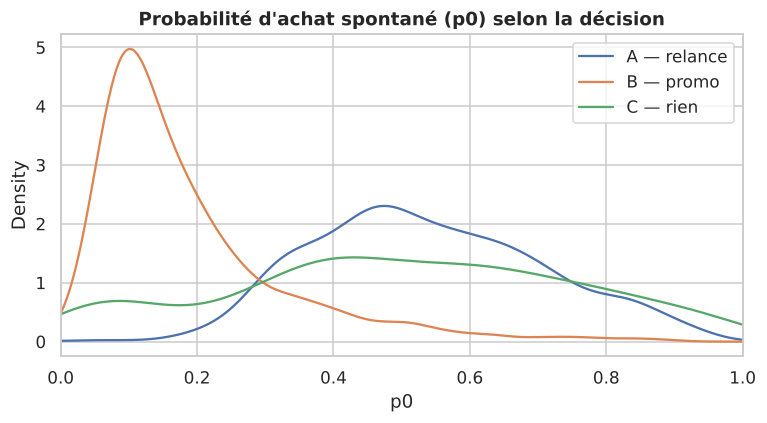

In [31]:
def decider(P, u=U_RELANCE, e=ELASTICITE, c=COUT_MSG, fenetre=7):
    habitude = (P.n_achats >= 3) & (P.intervalle_sd <= P.intervalle_moyen)        # achat répété et assez régulier
    depasse = habitude & P.indice_retard.between(1.5, 3) & (P.jours_depuis_achat <= 60)
    imminent = (P.delai_predit <= fenetre) & ~depasse
    C = P[imminent | depasse].copy()
    C["segment"] = np.where(depasse[imminent | depasse], "besoin dépassé", "besoin imminent")
    C["valeur"] = np.where(C.segment == "besoin dépassé",
                           C.marge * np.minimum(HORIZON_FIDELITE / C.intervalle_moyen.clip(lower=1), 6), C.marge)
    p0, V, R = C.proba_7j.values, C.valeur.values, C.prix.values
    C["gain_A"] = gain_A(p0, V, u)
    gB = np.column_stack([gain_B(p0, V, R, d, u, e) for d in REMISES])
    C["remise_optimale"] = np.array(REMISES)[gB.argmax(1)]
    C["gain_B"] = gB.max(1)
    C["option"] = np.where(C.gain_B > C.gain_A, "B — promo", "A — relance")
    C["gain"] = C[["gain_A", "gain_B"]].max(1)
    # 12 produits maximum par message : on garde les 12 plus rentables de chaque client (« pool »)
    C["pool"] = C["gain"].groupby(C.user_id).rank(ascending=False, method="first") <= 12
    C.loc[(C.gain <= 0) | ~C.pool, "option"] = "C — rien"
    utile = C.option != "C — rien"
    total = C[utile].groupby("user_id")["gain"].sum()
    envoyer = total[total > c].index
    C["decision"] = np.where(C.user_id.isin(envoyer) & utile, C.option, "C — rien")
    n_prod = C[C.decision != "C — rien"].groupby("user_id")["product_id"].transform("size")
    C["profit"] = 0.0
    C.loc[C.decision != "C — rien", "profit"] = C.loc[C.decision != "C — rien", "gain"] - c / n_prod
    C["remise"] = np.where(C.decision == "B — promo", C.remise_optimale, 0.0)
    # besoin dépassé : on relance dès demain
    C.loc[C.segment == "besoin dépassé", "date_envoi"] = END_DATE + pd.Timedelta(days=1)
    return C

C = decider(P)
print(f"Besoins détectés : {len(C):,} produits pour {C.user_id.nunique():,} clients")
display(pd.crosstab(C.segment, C.decision, margins=True, margins_name="Total"))
fig, ax = plt.subplots(figsize=(8, 3.8))
C.groupby("decision")["proba_7j"].plot(kind="kde", ax=ax, legend=True)
ax.set(title="Probabilité d'achat spontané (p0) selon la décision", xlabel="p0", xlim=(0, 1))
plt.show()

## 16. Volet 6 — Le panier personnalisé

In [32]:
def panier(client):
    b = C[(C.user_id == client) & (C.decision != "C — rien")].sort_values("date_prevue")
    b = b.assign(prix_final=(b.prix * (1 - b.remise)).round(2))
    return b[["product_name", "department", "segment", "date_prevue", "proba_7j", "decision", "remise", "prix", "prix_final", "profit"]]

def message(client):
    b = panier(client)
    h = int(C.loc[C.user_id == client, "heure_envoi"].iloc[0]); d = C.loc[C.user_id == client, "date_envoi"].min()
    lignes = "\n".join(f"  • {r.product_name} — {r.prix_final:.2f} $" + (f"  (-{r.remise:.0%})" if r.remise else "") for r in b.itertuples())
    return (f"Envoi prévu le {d:%d/%m/%Y} à {h} h\n\nObjet : Votre panier habituel est prêt\n\n"
            f"Bonjour, d'après vos habitudes, ces produits devraient bientôt vous manquer :\n{lignes}\n\n"
            f"Total : {b.prix_final.sum():.2f} $ — validez en un clic.")

clients_relances = C[C.decision != "C — rien"].groupby("user_id").size()
exemple = clients_relances[clients_relances.between(4, 8)].index[0]
print(f"Client {exemple} :"); display(panier(exemple).round(3))
print(message(exemple))

Client 63 :


,product_name,department,segment,date_prevue,proba_7j,decision,remise,prix,prix_final,profit
18,Apple Honeycrisp Organic,produce,besoin dépassé,2026-11-18,0.189,B — promo,0.200,0.660,0.530,0.115
11,Organic Broccoli Crowns,produce,besoin dépassé,2026-11-19,0.158,B — promo,0.200,1.350,1.080,0.240
67,Organic Plain Whole Milk Yogurt,dairy eggs,besoin dépassé,2026-11-21,0.123,B — promo,0.200,3.770,3.020,0.335
70,Organic Zucchini,produce,besoin dépassé,2026-11-23,0.097,B — promo,0.200,1.450,1.160,0.081


Envoi prévu le 01/11/2026 à 11 h

Objet : Votre panier habituel est prêt

Bonjour, d'après vos habitudes, ces produits devraient bientôt vous manquer :
  • Apple Honeycrisp Organic — 0.53 $  (-20%)
  • Organic Broccoli Crowns — 1.08 $  (-20%)
  • Organic Plain Whole Milk Yogurt — 3.02 $  (-20%)
  • Organic Zucchini — 1.16 $  (-20%)

Total : 5.79 $ — validez en un clic.


## 17. Volet 7 — Rentabilité de la campagne

On compare SupplyMe à des stratégies simples, sur **exactement les mêmes produits** (les 12 besoins les plus importants de chaque client).

,clients contactés,profit incrémental ($),coût des réductions ($),coût des messages ($)
stratégie,,,,
Aucune relance,0,0.000,0.000,0.000
"Relance à tous, sans réduction",1337,522.680,0.000,66.850
Promo -10 % à tous,1337,989.930,521.060,66.850
SupplyMe (ciblé),1274,"1,537.920",668.430,63.700


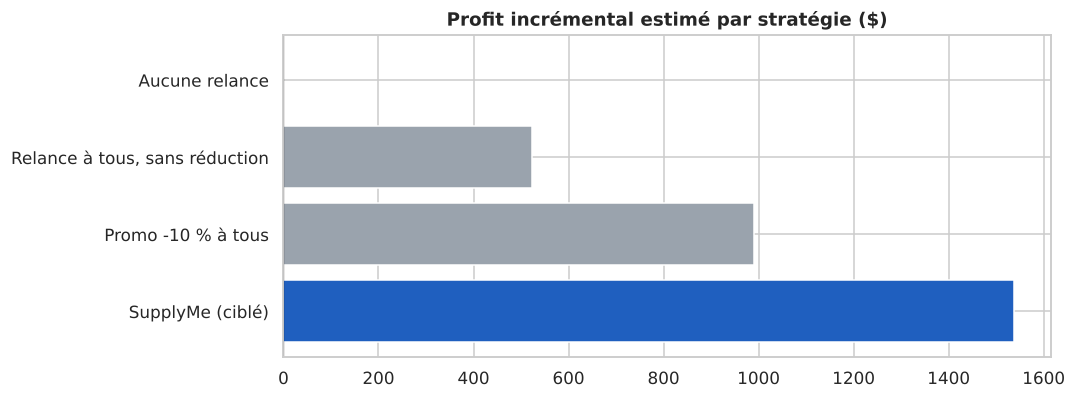

In [33]:
def strategies(C, u=U_RELANCE, e=ELASTICITE, c=COUT_MSG):
    C = C[C.pool]                                   # même ensemble de produits pour toutes les stratégies
    p0, m, R = C.proba_7j.values, C.valeur.values, C.prix.values
    n = C.user_id.nunique(); s = C.decision != "C — rien"
    rows = [("Aucune relance", 0, 0.0, 0.0),
            ("Relance à tous, sans réduction", n, gain_A(p0, m, u).sum() - n * c, 0.0),
            ("Promo -10 % à tous", n, gain_B(p0, m, R, 0.10, u, e).sum() - n * c, (proba_B(p0, 0.10, u, e) * 0.10 * R).sum()),
            ("SupplyMe (ciblé)", C.loc[s, "user_id"].nunique(), C.profit.sum(),
             (proba_B(p0[s], C.loc[s, "remise"].values, u, e) * C.loc[s, "remise"].values * R[s]).sum())]
    t = pd.DataFrame(rows, columns=["stratégie", "clients contactés", "profit incrémental ($)", "coût des réductions ($)"])
    t["coût des messages ($)"] = t["clients contactés"] * c
    return t.set_index("stratégie")

T = strategies(C)
display(T.round(2))
plt.figure(figsize=(9, 3.8))
plt.barh(T.index[::-1], T["profit incrémental ($)"][::-1], color=[BLUE, GREY, GREY, GREY])
plt.axvline(0, color=DARK, lw=0.8); plt.title("Profit incrémental estimé par stratégie ($)"); plt.show()

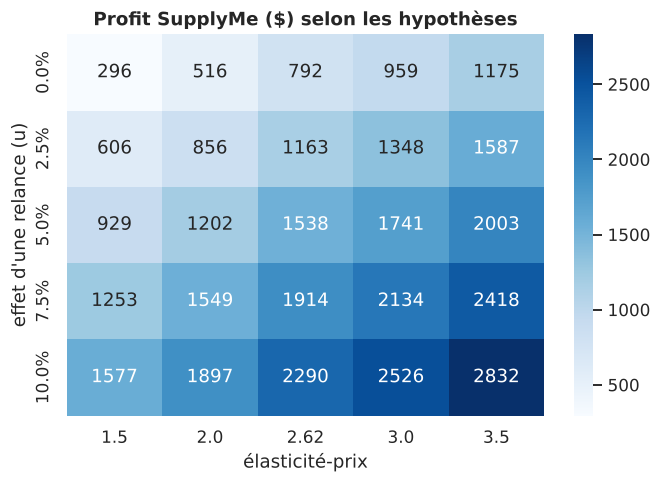

In [34]:
# Analyse de sensibilité : le résultat tient-il si nos hypothèses sont fausses ?
us, es = [0.0, 0.025, 0.05, 0.075, 0.10], [1.5, 2.0, 2.62, 3.0, 3.5]
sens = pd.DataFrame([[decider(P, u, e).profit.sum() for e in es] for u in us],
                    index=[f"{u:.1%}" for u in us], columns=[f"{e}" for e in es])
plt.figure(figsize=(7, 4.5))
sns.heatmap(sens, annot=True, fmt=".0f", cmap="Blues")
plt.title("Profit SupplyMe ($) selon les hypothèses"); plt.ylabel("effet d'une relance (u)"); plt.xlabel("élasticité-prix")
plt.show()

## 18. Conclusion

**Ce que montre l'analyse, volet par volet (base du groupe : 3 000 vrais clients Instacart) :**

1. **Historiques d'achat** : 16 commandes et 514 $ dépensés en moyenne par foyer sur un an. Les grands foyers ont des paniers plus gros.
2. **Habitudes** : 47 569 couples client × produit achetés au moins 3 fois, dont **80 %** réguliers ou très réguliers.
3. **Prédiction** : cinq approches comparées sur une période future jamais vue. Le délai est prédit avec **31 % d'erreur en moins** que la règle simple (LightGBM : 12,1 jours contre 17,5). La probabilité d'achat sous 7 jours, estimée par la régression logistique choisie sur la validation, atteint une **AUC de 0,789** (contre 0,739).
4. **Nouveaux clients** : panier de bienvenue, questionnaire avec points de fidélité, puis modèle à froid dès le 1er achat (AUC 0,742, erreur −37 %).
5. **Moment d'envoi** : 1 jour avant le besoin, 1 h avant l'heure habituelle de commande.
6. **Réduction** : inutile pour un besoin imminent (effet d'aubaine), rentable pour reconquérir une habitude en train d'être perdue.
7. **Rentabilité** : SupplyMe rapporte **1 538 $** de profit supplémentaire, contre **990 $** pour une promo de −10 % à tous et **523 $** pour une relance à tous, soit **+55 %**. Le profit reste **positif dans tous les scénarios testés** (de 296 $ à 2 832 $).

### Limites assumées
- Dates reconstruites, prix et foyers ancrés sur des sources officielles mais **simulés** au niveau individuel.
- Instacart plafonne les écarts à 30 jours : les cycles longs sont sous-estimés.
- Les réponses au questionnaire d'accueil sont fictives (base du groupe) : l'apport du questionnaire est une démonstration, pas une mesure.
- L'effet d'une relance et le coût d'un message sont des **hypothèses** : seul un vrai **A/B test** permettrait de les mesurer.

### Sources
- U.S. Bureau of Labor Statistics — *Average Price Data*, U.S. city average.
- NGA / FMS Solutions — *Independent Grocers Financial Survey* (2025) ; FMI — *Industry Speaks* (2021).
- U.S. Energy Information Administration — *RECS 2024*, table HC9.4.
- Bijmolt, T., Van Heerde, H., Pieters, R. (2005). *New Empirical Generalizations on the Determinants of Price Elasticity*. Journal of Marketing Research, 42(2), 141–156.

In [35]:
# Export des résultats (pour l'application Streamlit et le rapport)
OUT = "resultats_supplyme"
os.makedirs(OUT, exist_ok=True)
tab_reg.to_csv(f"{OUT}/comparaison_modeles_regression.csv")
tab_cls.to_csv(f"{OUT}/comparaison_modeles_classification.csv")
P.to_csv(f"{OUT}/predictions.csv", index=False)
C.to_csv(f"{OUT}/campagne.csv", index=False)
T.to_csv(f"{OUT}/strategies.csv")
print("Fichiers exportés dans", OUT, ":", sorted(os.listdir(OUT)))

Fichiers exportés dans resultats_supplyme : ['campagne.csv', 'comparaison_modeles_classification.csv', 'comparaison_modeles_regression.csv', 'predictions.csv', 'strategies.csv']
